In [73]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
from scipy.signal import resample
from astropy.io import fits
from astropy.table import Table
from astropy.table import vstack
from scipy.stats import ttest_rel
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import AutoMinorLocator
import os
import h5py
import emcee
import corner

FIG_DIR = "/raid/scratch/work/alberttg/Masters_project/Plots"

DATA_PRODUCTS_PATH = "/raid/scratch/work/alberttg/Masters_project/Data_products"

POSTERIOR_PATH = '/raid/scratch/work/austind/GALFIND_WORK/Bagpipes/pipes/posterior'

In [74]:
def weighted_reduced_chi_squared(y_obs, y_err_low, y_err_high, y_model, n_params,
                                  x_obs=None, x_err_low=None, x_err_high=None,
                                  gradient=None):
    """
    Calculate the reduced chi-squared for data with asymmetric uncertainties,
    optionally including x uncertainties projected onto y via the model gradient.

    Parameters
    ----------
    y_obs : array_like
        Observed y values.
    y_err_low : array_like
        Lower (negative) uncertainties on y.
    y_err_high : array_like
        Upper (positive) uncertainties on y.
    y_model : array_like
        Model predictions.
    n_params : int
        Number of fitted parameters.
    x_obs : array_like, optional
        Observed x values. Required if x_err_low/x_err_high are given.
    x_err_low : array_like, optional
        Lower (negative) uncertainties on x. If None, treated as zero.
    x_err_high : array_like, optional
        Upper (positive) uncertainties on x. If None, treated as zero.
    gradient : float, optional
        Local gradient of the model (dy/dx), used to project x uncertainty
        onto y. Required if x uncertainties are non-zero.

    Returns
    -------
    chi2_red : float
        Reduced chi-squared.
    """

    y_obs = np.asarray(y_obs, dtype=float)
    y_model = np.asarray(y_model, dtype=float)
    y_err_low = np.asarray(y_err_low, dtype=float)
    y_err_high = np.asarray(y_err_high, dtype=float)

    # Use the appropriate uncertainty depending on which side of the data
    sigma_y = np.where(y_model > y_obs, y_err_high, y_err_low)

    # Handle x uncertainties, if provided
    if x_err_low is None:
        x_err_low = np.zeros_like(y_obs)
    else:
        x_err_low = np.asarray(x_err_low, dtype=float)

    if x_err_high is None:
        x_err_high = np.zeros_like(y_obs)
    else:
        x_err_high = np.asarray(x_err_high, dtype=float)

    # If x errors are all zero, skip the x-error projection entirely —
    # this avoids requiring x_obs/gradient when there's nothing to project
    if np.all(x_err_low == 0) and np.all(x_err_high == 0):
        sigma = sigma_y
    else:
        if x_obs is None or gradient is None:
            raise ValueError("x_obs and gradient must be provided when x uncertainties are non-zero.")

        x_obs = np.asarray(x_obs, dtype=float)
        sigma_x = np.where(y_model > y_obs, x_err_high, x_err_low)

        # project x uncertainty onto y using the model gradient, combine in quadrature
        sigma = np.sqrt(sigma_y**2 + (gradient * sigma_x)**2)

    chi2 = np.sum(((y_obs - y_model) / sigma) ** 2)

    dof = len(y_obs) - n_params
    if dof <= 0:
        raise ValueError("Degrees of freedom must be positive.")

    chi2_red = chi2 / dof

    return chi2_red

In [75]:
def gaussian_function(x, sigma1, sigma2, mu, amp1, amp2):
    """
    1D Gaussian for a histogram density plot. Tall gaussiam is 1, stumpy gaussian is 2.
    """

    y1 = amp1 * np.exp( - ((x - mu)**2) / (2 * sigma1**2) )

    y2 = amp2 * np.exp( - ((x - mu)**2) / (2 * sigma2**2) )

    y = y1 + y2

    return y

In [76]:
def _parse_err(err, n):
    """
    Normalize an error specification into (err_lo, err_hi) arrays of length n.

    Accepted forms for `err`:
      - None                            -> zeros (no error)
      - scalar or 1D array of length n  -> symmetric error (same as before)
      - [err_high, err_low]             -> asymmetric error; each of
        err_high/err_low can be a scalar (applied to all points) or a
        length-n array (per-point)

    Returned lo/hi are positive distances from the central value
    (lower bound = value - lo, upper bound = value + hi).
    """
    if err is None:
        return np.zeros(n), np.zeros(n)

    # Asymmetric: [err_high, err_low]
    if isinstance(err, (list, tuple)) and len(err) == 2:
        hi = np.asarray(err[0], dtype=float) 
        lo = np.asarray(err[1], dtype=float)
        if hi.ndim == 0:
            hi = np.full(n, float(hi))
        if lo.ndim == 0:
            lo = np.full(n, float(lo))
        return lo.copy(), hi.copy()

    # Symmetric: scalar or array, same as before
    arr = np.asarray(err, dtype=float)
    if arr.ndim == 0:
        arr = np.full(n, float(arr))
    return arr.copy(), arr.copy()


def fit_gaussian_mcmc(corner_path, posterior_sum, x_in, y_in, x_err=None, y_err=None, x_pivot=None,
                     n_walkers=32, n_steps=5000, plot=True, save_path=None):
    """
    Bayesian gaussian fit without intrinsic scatter,
    supporting asymmetric measurement errors in both x and y (but we have none here).

    x_err / y_err each accept:
      - None, a scalar, or a 1D array of length N (symmetric errors, same
        as before), OR
      - [err_high, err_low] for asymmetric errors, where each of
        err_high/err_low is a scalar (applied to every point) or a
        length-N array (per-point).

    Asymmetric-error handling
    --------------------------
    Each data point's error distribution is modeled as a split-normal
    (two-piece Gaussian): width `sigma_lo` below the measured value and
    `sigma_hi` above it. At every MCMC step, for each point we compare the
    model prediction to the data (delta = model - data) and pick the
    error side consistent with that comparison:
        delta >= 0  ->  use the "hi" error (model sits above the data)
        delta <  0  ->  use the "lo" error (model sits below the data)
    This is applied to both the y errors and the x errors (the latter
    projected into y-space via the slope, m^2 * xerr^2, as in the
    symmetric case). This is the standard practical approximation for
    asymmetric errors in a likelihood — it is exact only when the true
    error distribution really is split-normal, but works well in general
    and reduces to the ordinary symmetric-error likelihood when lo == hi.
    The intrinsic scatter term sigma_int is kept symmetric.
    """
    # --- Step 1: Data Cleaning & Pivot Handling ---
    x = np.asarray(x_in, dtype=float)
    y = np.asarray(y_in, dtype=float)
    n = len(x)

    xe_lo, xe_hi = _parse_err(x_err, n)
    ye_lo, ye_hi = _parse_err(y_err, n)
    # xe_lo = np.zeros(n)
    # xe_hi = np.zeros(n)
    # ye_lo = np.zeros(n)
    # ye_hi = np.zeros(n)
    # My basic version of _parse_err function 

    xp = 0.0 if x_pivot is None else x_pivot
    
    mask = (
        np.isfinite(x) & np.isfinite(y)
        & np.isfinite(xe_lo) & np.isfinite(xe_hi)
        & np.isfinite(ye_lo) & np.isfinite(ye_hi)
    )

    x, y = x[mask], y[mask]
    xe_lo, xe_hi = xe_lo[mask], xe_hi[mask]
    ye_lo, ye_hi = ye_lo[mask], ye_hi[mask]
    n = len(x)

    # Guard against zero/negative error entries (keeps likelihood well-defined)
    xe_lo = np.where(xe_lo <= 0, 1e-10, xe_lo)
    xe_hi = np.where(xe_hi <= 0, 1e-10, xe_hi)
    ye_lo = np.where(ye_lo <= 0, 1e-10, ye_lo)
    ye_hi = np.where(ye_hi <= 0, 1e-10, ye_hi)

    #print(xe_lo)
    #print(xe_hi)
    #print(ye_lo)
    #print(ye_hi)

    if len(x) < 2:
        raise ValueError("Not enough finite data points.")

    # --- Step 2: Robust Initial Guess ---
    try:
        popt, pcov = curve_fit(gaussian_function, x - xp, y, p0=[np.std(x-xp), np.std(x-xp), np.mean(x-xp), np.max(y), np.max(y)], bounds=([1e-5, 1e-5, -np.inf, 0, 0], [10.0, 10.0, np.inf, np.inf, np.inf]))
        guess_sig1, guess_sig2, guess_mu, guess_amp1, guess_amp2 = popt
        guess_sig1 = np.abs(guess_sig1)
        guess_sig2 = np.abs(guess_sig2)
        print(f"Guesses: sig = {guess_sig1:.3f}, sig = {guess_sig2:.3f}, mean = {guess_mu:.3f}, amplitude = {guess_amp1:.3f}, amplitude = {guess_amp2:.3f}")
    
    except np.linalg.LinAlgError:
        guess_sig1, guess_sig2, guess_mu, guess_amp1, guess_amp2 = np.std(x-xp), np.std(x-xp), np.mean(x-xp), np.max(y), np.max(y)

    # guess_std = np.std(y - gaussian_function(x-xp, guess_sig, guess_mu, guess_amp))

    # --- Step 3: MCMC Functions (3 parameters: m, c, sigma_int) ---
    def log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        sig1, sig2, mu, amp1, amp2 = theta
        # if sigma_int <= 0: this was one of the params
        #    return -np.inf

        model = gaussian_function((x-xp), sig1, sig2, mu, amp1, amp2)
        # delta = model - y  # positive => model above data

        delta = x - xp

        y_err = np.where(delta >= 0, yerr_hi, yerr_lo)
        x_err = np.where(delta >= 0, xerr_hi, xerr_lo)

        n = len(x) # no. of data points

        ln_L = -0.5 * np.sum(np.log(2 * np.pi * y_err**2)) - 0.5 * np.sum(((y - model) / y_err)**2)
        # ln_L = - (n/2) * np.log(2*np.pi) - n * np.log(sig) - 0.5 * np.sum( ((delta - mu)  / sig)**2)

        return ln_L

    # Set prior limits safely outside empirical distribution boundaries
    min_sig1, max_sig1 = 1e-4, guess_sig1 * 3.0
    min_sig2, max_sig2 = 1e-4, guess_sig2 * 3.0
    min_mu, max_mu = guess_mu - (3 * guess_sig2), guess_mu + (3 * guess_sig2)
    min_amp1, max_amp1 = 0.4 * guess_amp1, 1.5 * guess_amp1
    min_amp2, max_amp2 = 0.4 * guess_amp2, 1.5 * guess_amp2

    def log_prior(theta): 
        """
        Uses Jeffrey's prior (log-uniform) instead of flat uniform prior.
        """
        sig1, sig2, mu, amp1, amp2 = theta

        # sig2 should be > sig1 and amp2 < amp1

        conditions = (sig1 < max_sig1 and min_mu < mu < max_mu and min_amp1 < amp1 < max_amp1 \
                      and min_sig2 < sig2 < max_sig2 and min_amp2 < amp2 < max_amp2 \
                      and sig2 > sig1 and amp2 < amp1)
        
        if conditions:
            return 0 # This is return 0 for flat uniform prior
        return -np.inf

    def log_probability(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        ll = log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp)
        return lp + ll if np.isfinite(ll) else -np.inf

    # --- Step 4: Run MCMC ---
    ndim = 5
    # initial = np.array([guess_sig, guess_mu, guess_amp if guess_std > 0 else 0.1]) old
    initial = np.array([guess_sig1, guess_sig2, guess_mu, guess_amp1, guess_amp2])
    pos = initial + 1e-4 * np.random.randn(n_walkers, ndim)

    sampler = emcee.EnsembleSampler(
        n_walkers, ndim, log_probability,
        args=(x, y, xe_lo, xe_hi, ye_lo, ye_hi, xp)
    )
    sampler.run_mcmc(pos, n_steps, progress=True)

    flat_samples = sampler.get_chain(discard=1000, thin=15, flat=True)

    x_range = np.linspace(x.min(), x.max(), 100)
    sig1_samples = flat_samples[:, 0]
    sig2_samples = flat_samples[:, 1]
    mu_samples = flat_samples[:, 2]
    amp1_samples = flat_samples[:, 3]
    amp2_samples = flat_samples[:, 4]

    models = gaussian_function((x_range - xp), sig1_samples[:, np.newaxis], sig2_samples[:, np.newaxis], 
                                mu_samples[:, np.newaxis], 
                                amp1_samples[:, np.newaxis], amp2_samples[:, np.newaxis])

    sig1_med, sig2_med, mu_med, amp1_med, amp2_med = np.median(flat_samples, axis=0)
    lower_bound = np.percentile(models, 16, axis=0)
    upper_bound = np.percentile(models, 84, axis=0)

    # --- Step 5: Visualization ---
    if plot:
        """
        plt.figure(figsize=(8, 6))
        print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")

        # matplotlib expects asymmetric errors as [lower_distances, upper_distances]
        # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
        
        plt.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
        plt.plot(x_range, gaussian_function((x_range - xp), sig_med, mu_med, amp_med), color="darkblue", lw=2, label="Median Fit")
        plt.legend()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.show()
        """

        labels = [r"Sigma 1 $\sigma_{1}$", r"Sigma 2 $\sigma_{2}$", f"Mean $\mu$ (at $x={xp}$)", "Amplitude 1", "Amplitude 2"]
        corner.corner(flat_samples, labels=labels, truths=[sig1_med, sig2_med, mu_med, amp1_med, amp2_med], show_titles=True)
        plt.savefig(corner_path, dpi=150)
        plt.show()

    sig1_16 = np.percentile(flat_samples[:, 0], 16)
    sig1_84 = np.percentile(flat_samples[:, 0], 84)

    fwhm1_med = np.sqrt(8 * np.log(2)) * sig1_med
    fwhm1_upp_err = np.sqrt(8 * np.log(2)) * (sig1_84 - sig1_med)
    fwhm1_low_err = np.sqrt(8 * np.log(2)) * (sig1_med - sig1_16)

    sig2_16 = np.percentile(flat_samples[:, 0], 16)
    sig2_84 = np.percentile(flat_samples[:, 0], 84)

    fwhm2_med = np.sqrt(8 * np.log(2)) * sig1_med
    fwhm2_upp_err = np.sqrt(8 * np.log(2)) * (sig1_84 - sig1_med)
    fwhm2_low_err = np.sqrt(8 * np.log(2)) * (sig1_med - sig1_16)

    red_chi2 = weighted_reduced_chi_squared(y_obs=y, y_err_low=ye_lo, y_err_high=ye_hi, 
                                            y_model=gaussian_function((x-xp), sig1_med, sig2_med, mu_med, amp1_med, amp2_med), 
                                            n_params=5,
                                            x_obs=None, x_err_low=None, x_err_high=None,
                                            gradient=None)
    print(f"Reduced chi squared = {red_chi2:.3f}")

    results = {
        "sigma1_median": sig1_med,
        "sigma2_median": sig2_med,
        "mean_median": mu_med,
        "amplitude1": amp1_med,
        "amplitude2": amp2_med,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "sig1_16": np.percentile(flat_samples[:, 0], 16),
        "sig1_84": np.percentile(flat_samples[:, 0], 84),
        "sig2_16": np.percentile(flat_samples[:, 1], 16),
        "sig2_84": np.percentile(flat_samples[:, 1], 84),
        "mu_16": np.percentile(flat_samples[:, 2], 16),
        "mu_84": np.percentile(flat_samples[:, 2], 84),
        "amp1_16": np.percentile(flat_samples[:, 3], 16),
        "amp1_84": np.percentile(flat_samples[:, 3], 84),
        "amp1_16": np.percentile(flat_samples[:, 4], 16),
        "amp1_84": np.percentile(flat_samples[:, 4], 84),
        "x_pivot": xp,
        "x_range": x_range,
        "fwhm1": fwhm1_med,
        "fwhm1_upper_error": fwhm1_upp_err,
        "fwhm1_lower_error": fwhm1_low_err,
        "fwhm2": fwhm1_med,
        "fwhm2_upper_error": fwhm1_upp_err,
        "fwhm2_lower_error": fwhm1_low_err,
        "reduced_chi_squared": red_chi2,
        "centres": x,
        "counts": y,
        "yerr": ye_hi,
        "posterior_sum": posterior_sum,
    }

    return results

In [77]:
def get_posterior(sample_table, SFH_model, refit=False):
    """
    Finding the paths to the stellar mass posterior, based on galaxy survey id, survey and SFH model used in BAGPIPES.
    Each galaxy has its own posterior.
    """

    surveys = np.asarray(sample_table["SURVEY"].data, dtype=str)

    survey_ids = np.asarray(sample_table["#ID"].data, dtype=int)

    redshifts = np.asarray(sample_table["input_redshift"].data, dtype=float)

    mass = np.asarray(sample_table["stellar_mass_50"].data, dtype=float)

    src_corr = np.asarray(sample_table["ext_src_corr_0.32as_F444W"].data, dtype=float)

    posteriors = []

    for i in range(len(sample_table)):

        gal_id = survey_ids[i]
        survey = surveys[i]
        redshift = redshifts[i]
        corr = src_corr[i]

        if survey in ["CEERSP1", "CEERSP2", "CEERSP3", "CEERSP4", "CEERSP5", "CEERSP6", "CEERSP7", "CEERSP8", "CEERSP9", "CEERSP10", "NEP-1", "NEP-2", "NEP-3", "NEP-4", "NGDEEP"]:

            path = os.path.join(POSTERIOR_PATH, f"v14_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")

        elif survey in ["PRIMER-COSMOS","PRIMER-UDS"]:
                
            path = os.path.join(POSTERIOR_PATH, f"v12_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")


        elif survey in ["JADES-DR3-GS-East", "JADES-DR3-GS-North", "JADES-DR3-GS-South", "JADES-DR3-GS-West", "JADES-DR3-GN-Parallel", "JADES-DR3-GN-Medium", "JADES-DR3-GN-Deep"]:

            path = os.path.join(POSTERIOR_PATH, f"v13_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")
            
        else:
            print(f"Galaxy {gal_id} could not be found in these surveys")
            print(f"Check survey {survey}")
            continue


        with h5py.File(path,'r') as hf:
            # Print all root level object names (aka keys) 
            # these can be group or dataset names 
            # print("Keys: %s" % hf['basic_quantities'].keys())
            # print("Keys: %s" % hf['advanced_quantities'].keys())
            stellar_mass = hf['basic_quantities']['stellar_mass'][:]
            
        stellar_mass = stellar_mass * corr
        median_mass = np.median(stellar_mass)
        log_mass = np.array(stellar_mass - median_mass)

        if len(log_mass) != 500:
            print("Length not 500: ", len(log_mass))
            print(f"Check the posterior of galaxy {gal_id} in survey {survey} ")
            log_mass = resample(x=log_mass, num=500, axis=0)
            print(f"Posterior of galaxy {gal_id} in survey {survey} is resampled")

        posteriors.append(log_mass) # ought to be in same order as mass and redshift are ordered, which is by ith row of sample table

    # print(posteriors)
    
    plot_binned_posterior(mass, redshifts, posteriors, 50, refit=refit) # I think the posterior are in the same order as galaxy table (mass, redshift...)

    

In [78]:
def calculate_hist_data(posterior_sum, histogram_bins):
    """
    Histogram the posterior data into n_bins=histrogram_bins.
    """
    raw_counts, edges = np.histogram(posterior_sum, bins=histogram_bins)
    centres = 0.5 * (edges[1:] + edges[:-1])
    yerr = np.sqrt(np.maximum(raw_counts, 1)) # Poisson errors on hist density

    # Calculate the normalization factor used by density=True
    bin_widths = np.diff(edges)
    total_counts = len(posterior_sum)
    normalization = total_counts * bin_widths

    # Calculate density and its corresponding scaled error
    counts = raw_counts / normalization
    # Apply Poisson error on raw counts, safely handling zero-bins with np.maximum
    yerr = np.sqrt(np.maximum(raw_counts, 1)) / normalization

    return centres, counts, yerr
    

In [ ]:
def trim_and_refit(m, z, centres, counts, yerr, posterior_sum, histogram_bins, results):
    """
    If the histogram centres data has really long tails and a narrow peak, 
    trim the posterior_sum from which the histogram was initially applied,
    then repeat the histogram and fitting process.
    """
    print(f"Posterior: {np.min(posterior_sum):.3f} -- {np.max(posterior_sum):.3f}, length = {len(posterior_sum)}")

    sig2_med = results["sigma2_median"] # choosing the fattest one
    mu_med = results["mean_median"]

    n_sig = 5 # how many sigma away from mean within which to recalculate posterior_sum and histogram

    if (np.max(centres) > mu_med + n_sig * sig2_med) or (np.min(centres) < mu_med - n_sig * sig2_med):

        print("Tails too long, trimming posterior and refitting.")

        trim_mask = (posterior_sum <= mu_med + n_sig * sig2_med) & (posterior_sum >= mu_med - n_sig * sig2_med)
        posterior_sum = posterior_sum[trim_mask]

        centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins)

        results = fit_gaussian_mcmc(os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Lorentzian_corner_plots/corner_{m}_{z}.png"),
                                        posterior_sum,
                                        centres, counts, 
                                        x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)

        return results

    else:
        return results

In [ ]:
def plot_binned_posterior(mass, redshift, posterior, histogram_bins, refit=False):
    """
    Sorting the posterior into bins, selected by mass and redshift value.

    mass : array of floats
        The mass values of all the galaxies
    redshift : array of floats
        The zfix redshift values of all the galaxies
    posterior : array of arrays of floats
        The posterior for each galaxy, which are each an array.
    histogram_bins : float
        Number of histogram bins for each plot and also for gaussian fitting
    refit : bool
        User decides whether or not to refit.
    """
    z_bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]

    fig, axes = plt.subplots(3, 6, figsize=(35,18), constrained_layout=True)
    # Starting binning, bin by mass first (vertical bins)
    # mass_bins = np.linspace(mass.min(), mass.max(), n_mass_bins + 1)
    # mass_bins = [[mass_bins[i], mass_bins[i + 1]] for i in range(len(mass_bins) - 1)]
    # mass_bins.reverse()
    #print("Mass bins: ", mass_bins)
    mass_bins = [[9.0,11], [8,9.0], [5,8]] # Have put them in reverse for the gridspec plotting

    for i in range(len(mass_bins)):

        bin_width = mass_bins[i][1] - mass_bins[i][0]

        mass_bin_mask = (mass >= mass_bins[i][0]) & (mass < mass_bins[i][1]) # Splitting into mass bins

        redshift_m_binned = redshift[mass_bin_mask]
        mass_errors_m_binned = mass[mass_bin_mask]
        
        posterior_m_binned = [item for item, m in zip(posterior, mass_bin_mask) if m]


        # Now bin by z (horizontal bins)
        for j in range(len(z_bins)):

            z_bin_mask = (redshift_m_binned >= z_bins[j][0]) & (redshift_m_binned < z_bins[j][1])

            redshift_z_binned = redshift_m_binned[z_bin_mask]
            mass_z_binned = mass_errors_m_binned[z_bin_mask] # x axis values now binned by z and mass

            print("m bin: ", mass_bins[i])
            print("z bin: ", z_bins[j])
            print("Number of gals in bin: ", len(redshift_z_binned))

            posterior_z_binned = [item for item, m in zip(posterior_m_binned, z_bin_mask) if m]

            # [print(len(p)) for p in posterior_z_binned] # this checks that most posterior are length 500, but one is 106 and one is 107

            if len(posterior_z_binned) == 0:
                continue  # or leave the axis empty

            # --------------------------------------------- binning complete -----------------------------------------------
            # Now calculating posterior sum and making into a normalised histogram

            posterior_sum = np.concatenate(posterior_z_binned, axis=0)  # was trying this to see combined distribution of mass offsets for the galaxies in a bin
            # posterior_sum = [sum(p) for p in zip(*posterior_z_binned)] # idk about this one...
            # print("sum shape: ", np.shape(posterior_sum))

            # ------------------------------------------------ mcmc fitting ------------------------------------------------
            # Create the HDF5 file
            if i == 0:
                m = "m>9.5"
            if i == 1:
                m = "m=8-9.5" # centre of mass bin
            if i == 2:
                m = "m<8"
            z = f"z={0.5*(z_bins[j][0] + z_bins[j][1])}" # centre of redshift bin

            file_path = os.path.join(DATA_PRODUCTS_PATH, "Gridspec_mass_errors", "Double_gaussian_fit_results", f"results_table_{m}_{z}.h5")
    
            if os.path.exists(file_path) and not refit:
                # Load previously saved fit results
                with h5py.File(file_path, 'r') as hf:
                    results = {key: hf[key][()] for key in hf.keys()}
                print(f"Loaded existing results from {file_path}")

            else:
                centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins) # Initial calculation

                results = fit_gaussian_mcmc(os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Double_gaussian_corner_plots/corner_{m}_{z}.png"),
                                            posterior_sum,
                                            centres, counts, 
                                            x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)

                results = trim_and_refit(m, z, centres, counts, yerr, posterior_sum, histogram_bins, results)
                # Refitted if needed to trim data
                with h5py.File(file_path, 'w') as hf:
                    for key, val in results.items():
                        hf.create_dataset(key, data=val)
                print(f"Saved to {file_path}")


            sig1_med = results["sigma1_median"]
            mu_med = results["mean_median"]
            amp1_med = results["amplitude1"]
            sig2_med = results["sigma2_median"]
            amp2_med = results["amplitude2"]
            x_range = results["x_range"]
            x_pivot = results["x_pivot"]
            lower_bound = results["lower_bound"]
            upper_bound = results["upper_bound"]
            fwhm1 = results["fwhm1"]
            fwhm2 = results["fwhm2"]
            centres = results["centres"]
            counts = results["counts"]
            posterior_sum = results["posterior_sum"]

            half_max1 = amp1_med / 2
            half_max2 = amp2_med / 2

            left_crossing1 = centres[np.argmax(counts)] - sig1_med # should probably use mu_med but cba
            right_crossing1 = centres[np.argmax(counts)] + sig1_med

            left_crossing2 = centres[np.argmax(counts)] - sig2_med # should probably use mu_med but cba
            right_crossing2 = centres[np.argmax(counts)] + sig2_med
            

            # ---------------------------------------------- Plotting -------------------------------------------
            
            ax = axes[i,j]
                    
            # ax.set_ylabel(r'Probability density \left( $\sigma_{M_\star}^{-1}$ \right)', fontsize=16)
            if j == 0:
                if i == 0:
                    ax.set_ylabel(rf"$\log_{10}(M_\star/M_\odot) ≥ 9.5$", fontsize=16)
                if i == 1:
                    ax.set_ylabel(rf"$8.0 ≤ \log_{10}(M_\star/M_\odot) < 9.5$", fontsize=16)
                if i == 2:
                    ax.set_ylabel(rf"$\log_{10}(M_\star/M_\odot) < 8.0$", fontsize=16)
                
            
            ax.grid(True)

            # print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")
    
            # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
            
            ax.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
            ax.plot(x_range, gaussian_function((x_range - x_pivot), sig1_med, sig2_med, mu_med, amp1_med, amp2_med), color="darkblue", lw=2, label="Median Fit")
            ax.legend(fontsize=14)

            ax.tick_params(
                    axis="both",
                    which="major",
                    labelsize=14,
                    length=8,
                    width=1.5,
                    direction="in",
                    top=True,
                    right=True
                    )
            
            ax.xaxis.set_minor_locator(AutoMinorLocator(5))
            ax.yaxis.set_minor_locator(AutoMinorLocator(5))

            ax.tick_params(
                    axis="both",
                    which="minor",
                    length=4,
                    width=1,
                    direction="in",
                    top=True,
                    right=True
                    )

            ax.hist(posterior_sum, bins=histogram_bins, color='steelblue', density=True)

            ax.axhline(half_max1, color='black', linestyle='--', label='Half maximum')
            
            ax.axvline(x=left_crossing1, ymin=0, ymax=0.5, color='purple', linestyle=':')
            ax.axvline(x=right_crossing1, ymin=0, ymax=0.5,  color='purple', linestyle=':')

            ax.fill_between(
                [left_crossing1, right_crossing1],
                [0, 0],
                [half_max1, half_max1],
                alpha=0.3,
                color='purple',
                label=f'FWHM 1 (lanky) = {fwhm1:.3f}'
            )

            ax.axvline(x=left_crossing2, ymin=0, ymax=half_max2/np.max(counts), color='red', linestyle=':')
            ax.axvline(right_crossing2, ymin=0, ymax=half_max2/np.max(counts),  color='red', linestyle=':')
            
            ax.fill_between(
                [left_crossing2, right_crossing2],
                [0, 0],
                [half_max2, half_max2],
                alpha=0.3,
                color='red',
                label=f'FWHM 2 (stocky) = {fwhm2:.3f}'
            )

            ax.legend(loc="upper left", fontsize=14)

            ax.set_xlim( (mu_med - 6 * sig1_med), (mu_med + 6 * sig1_med) )

            legend_text = rf"${z_bins[j][0]} ≤ z < {z_bins[j][1]}$"
            ax.text(0.6, 0.95, legend_text, transform=ax.transAxes, fontsize=15, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    fig.supylabel(r'Histogram density', fontsize=20)
    fig.supxlabel(r'Stellar Mass $\log_{10}(M_\star/M_\odot) - \langle( \log_{10}(M_\star/M_\odot) \rangle $', fontsize=20)
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "Gridspec_mass_errors", "gridspec_mass_errors_double_gaussian.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


Length not 500:  106
Check the posterior of galaxy 11825 in survey NEP-4 
Posterior of galaxy 11825 in survey NEP-4 is resampled
Length not 500:  117
Check the posterior of galaxy 96942 in survey PRIMER-UDS 
Posterior of galaxy 96942 in survey PRIMER-UDS is resampled
m bin:  [9.0, 11]
z bin:  [6.5, 7.5]
Number of gals in bin:  50
Guesses: sig = 0.049, sig = 0.149, mean = 0.003, amplitude = 4.184, amplitude = 1.202


100%|██████████| 5000/5000 [00:06<00:00, 721.58it/s]


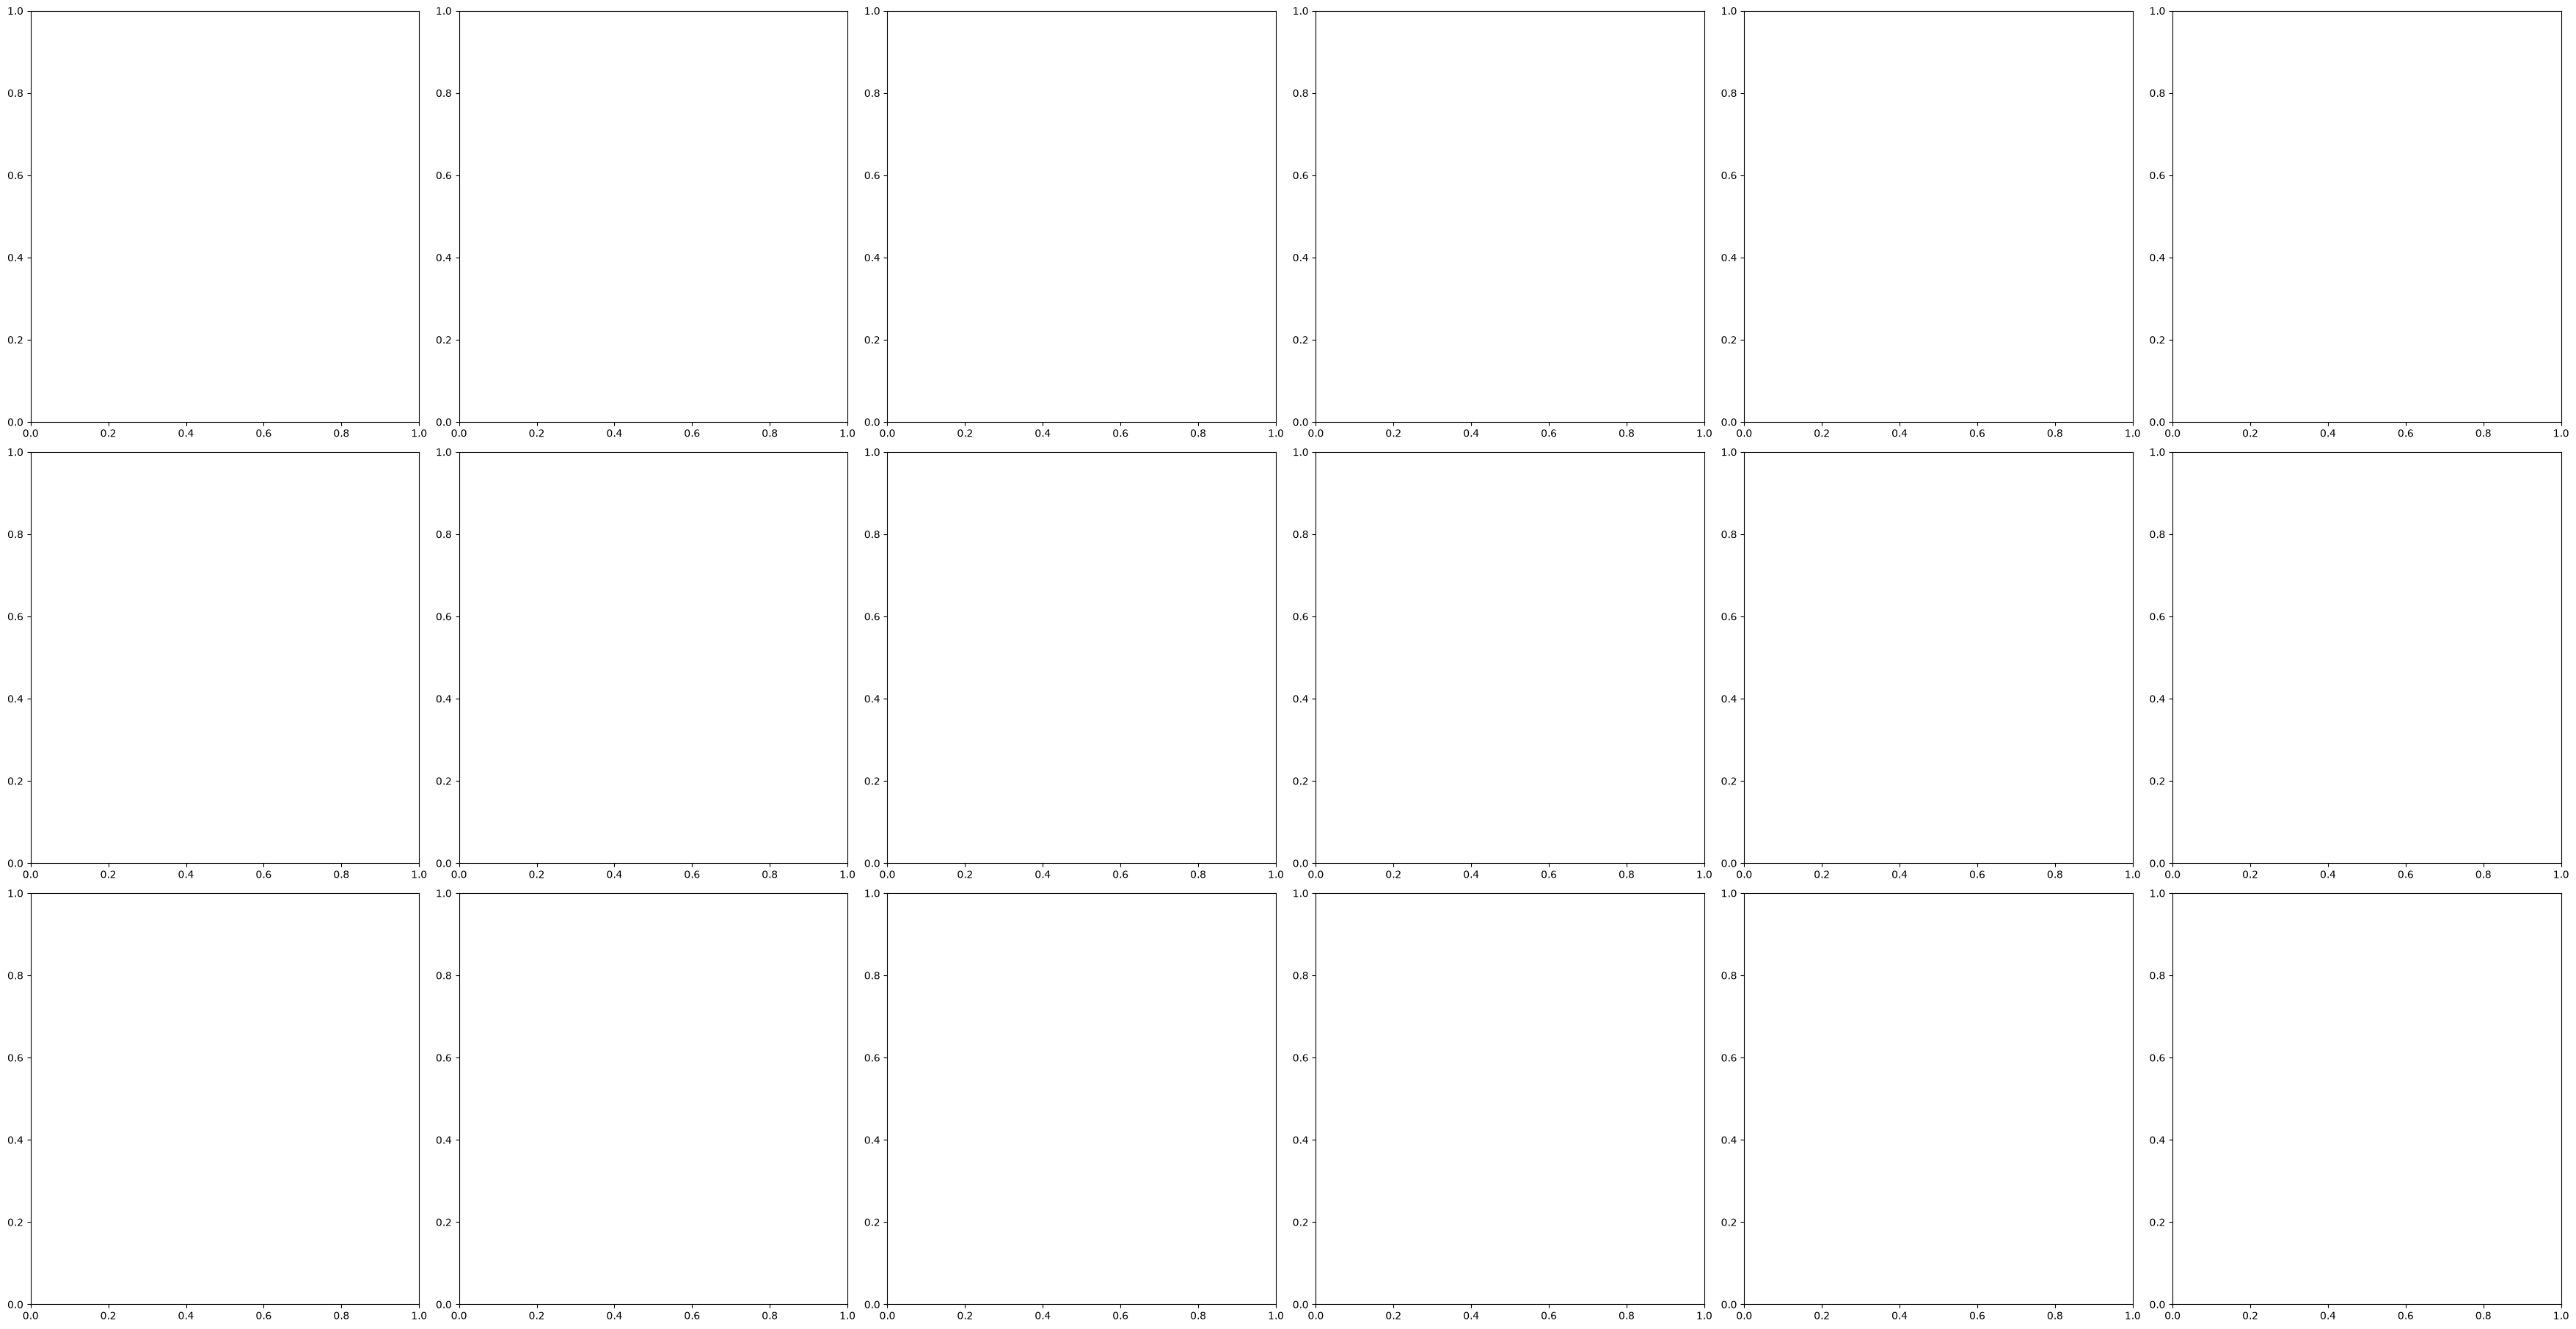

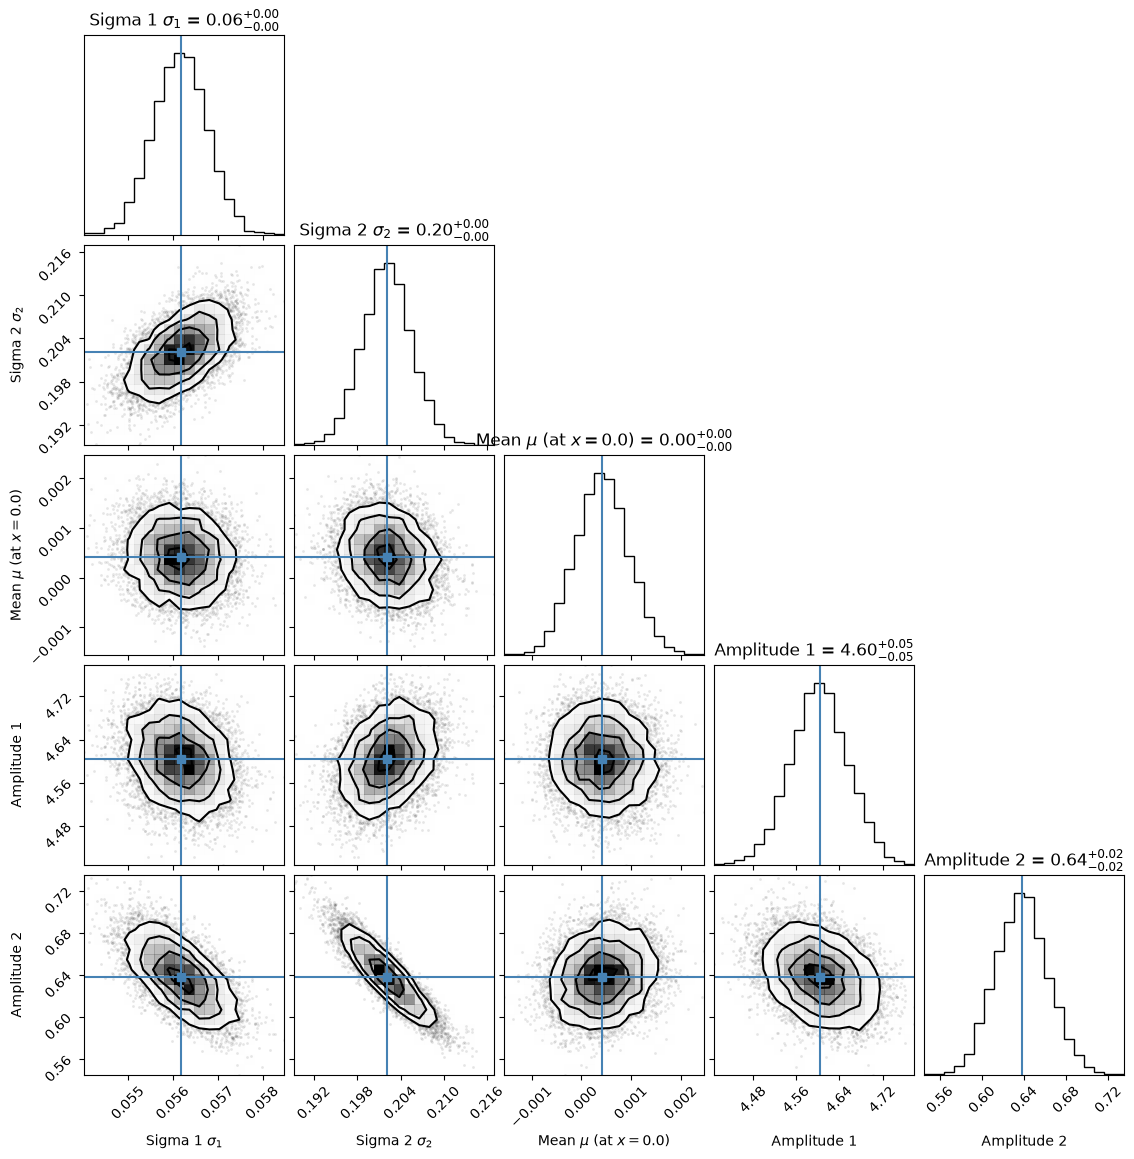

Reduced chi squared = 15.815
Posterior: -3.215 -- 1.422, length = 25000
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.133, sig = 0.041, mean = -0.001, amplitude = 1.471, amplitude = 4.543


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1916.99it/s]


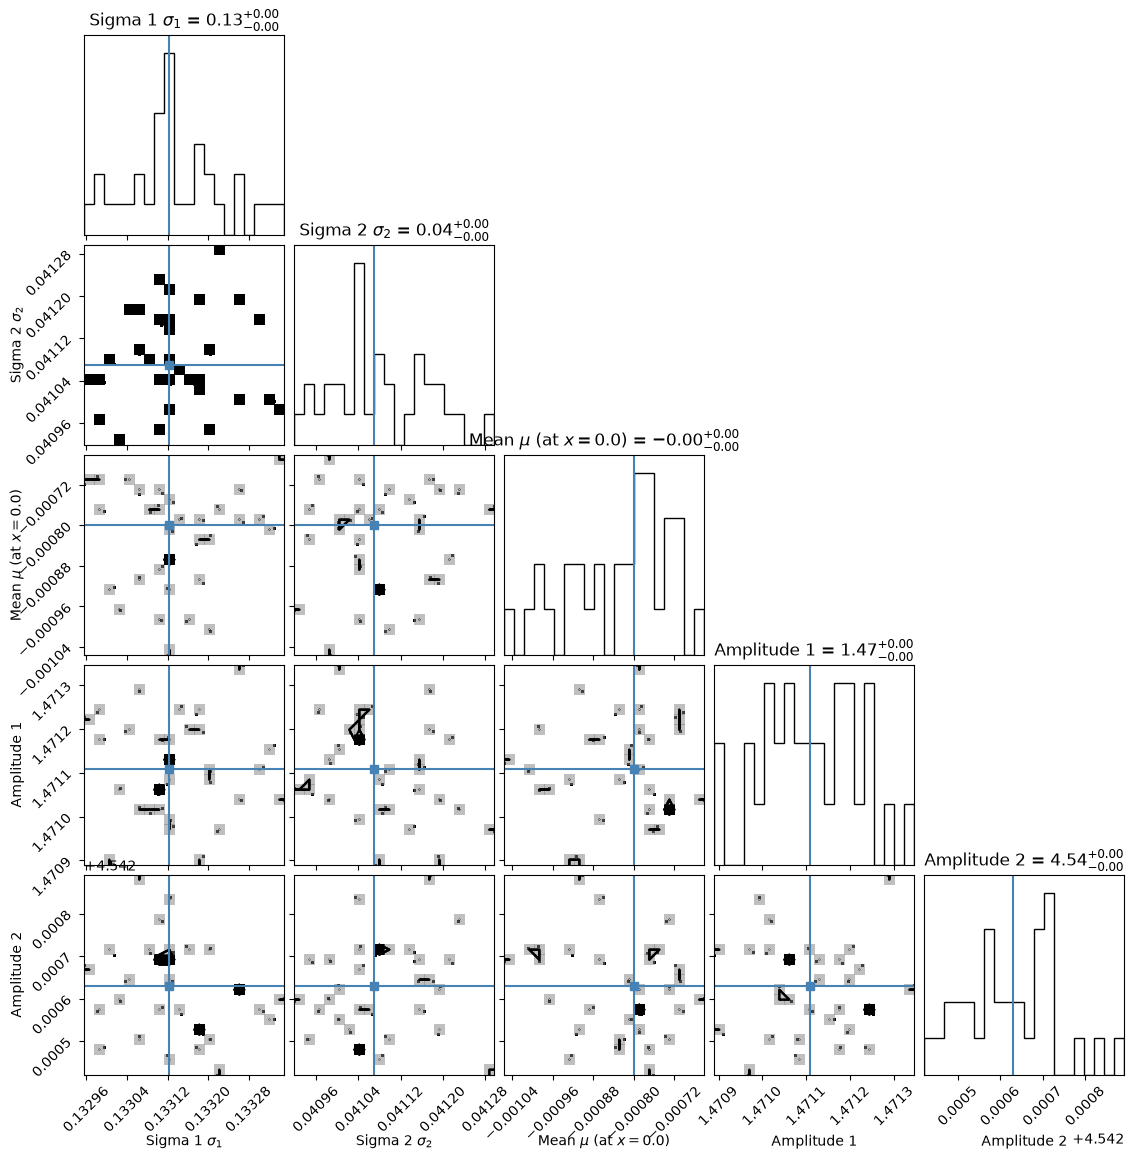

Reduced chi squared = 26.247
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m>9.5_z=7.0.h5
m bin:  [9.0, 11]
z bin:  [7.5, 8.5]
Number of gals in bin:  10
Guesses: sig = 0.052, sig = 0.255, mean = 0.002, amplitude = 4.630, amplitude = 0.589


100%|██████████| 5000/5000 [00:07<00:00, 667.03it/s]


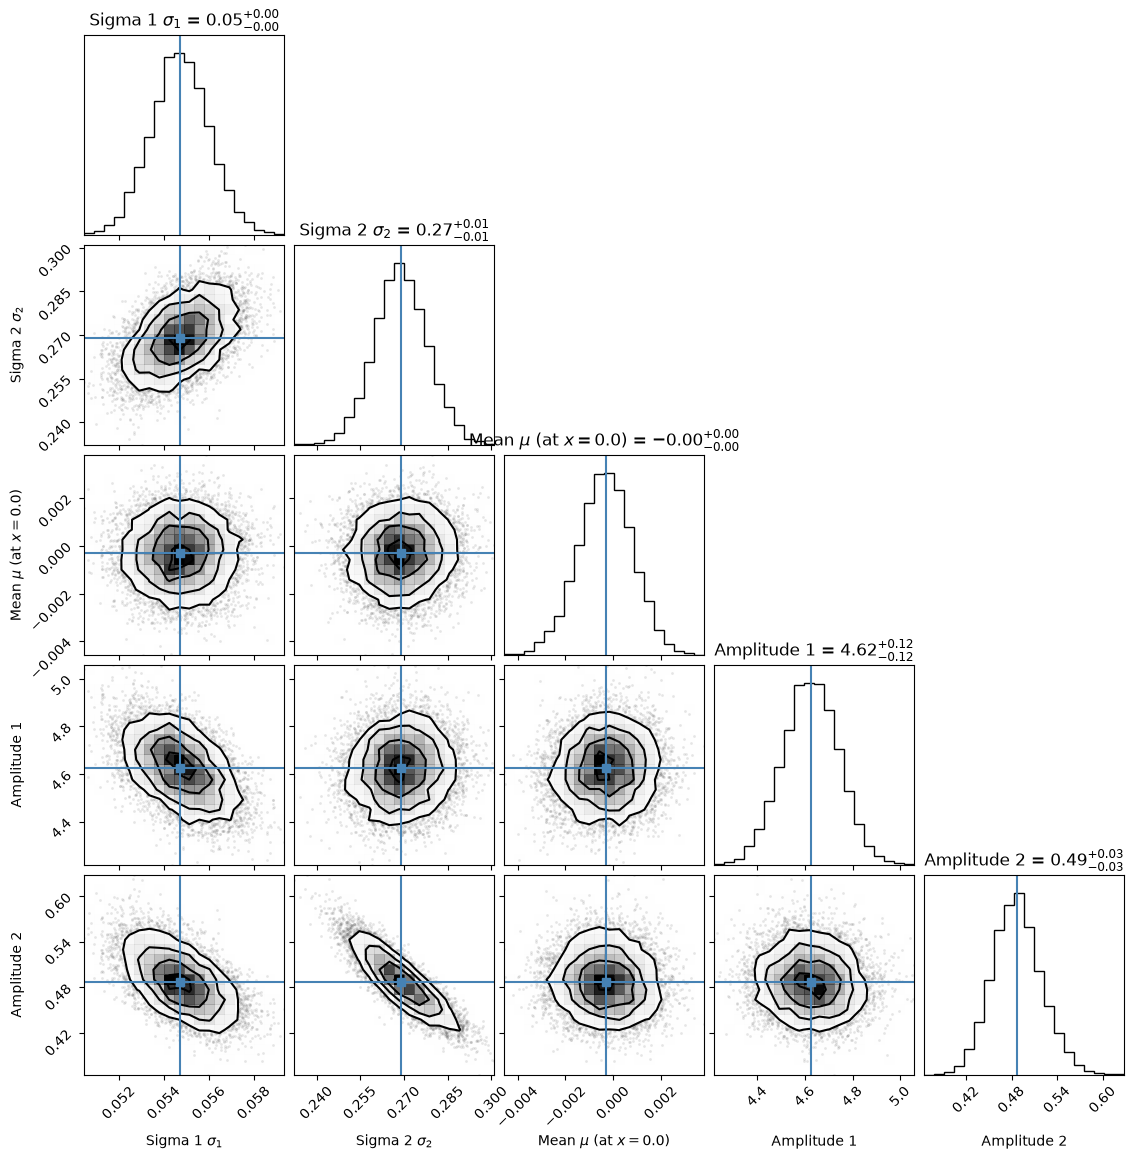

Reduced chi squared = 4.215
Posterior: -1.267 -- 1.098, length = 5000
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m>9.5_z=8.0.h5
m bin:  [9.0, 11]
z bin:  [8.5, 9.5]
Number of gals in bin:  6
Guesses: sig = 0.093, sig = 0.028, mean = 0.001, amplitude = 2.475, amplitude = 5.976


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2034.74it/s]


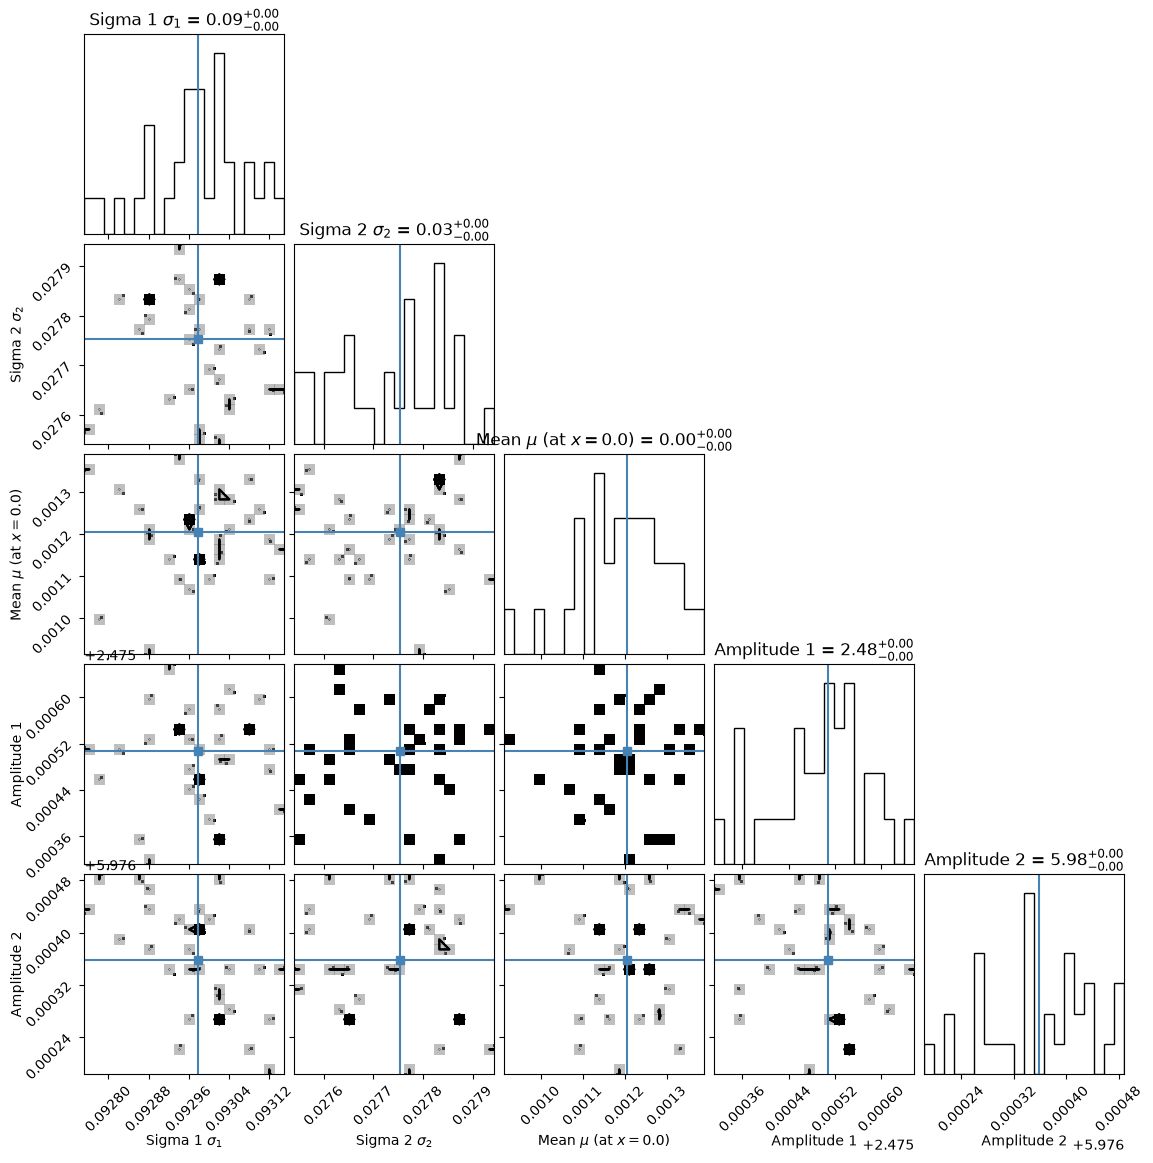

Reduced chi squared = 1.467
Posterior: -1.476 -- 0.429, length = 3000
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.101, sig = 0.027, mean = 0.000, amplitude = 2.376, amplitude = 7.297


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2302.07it/s]


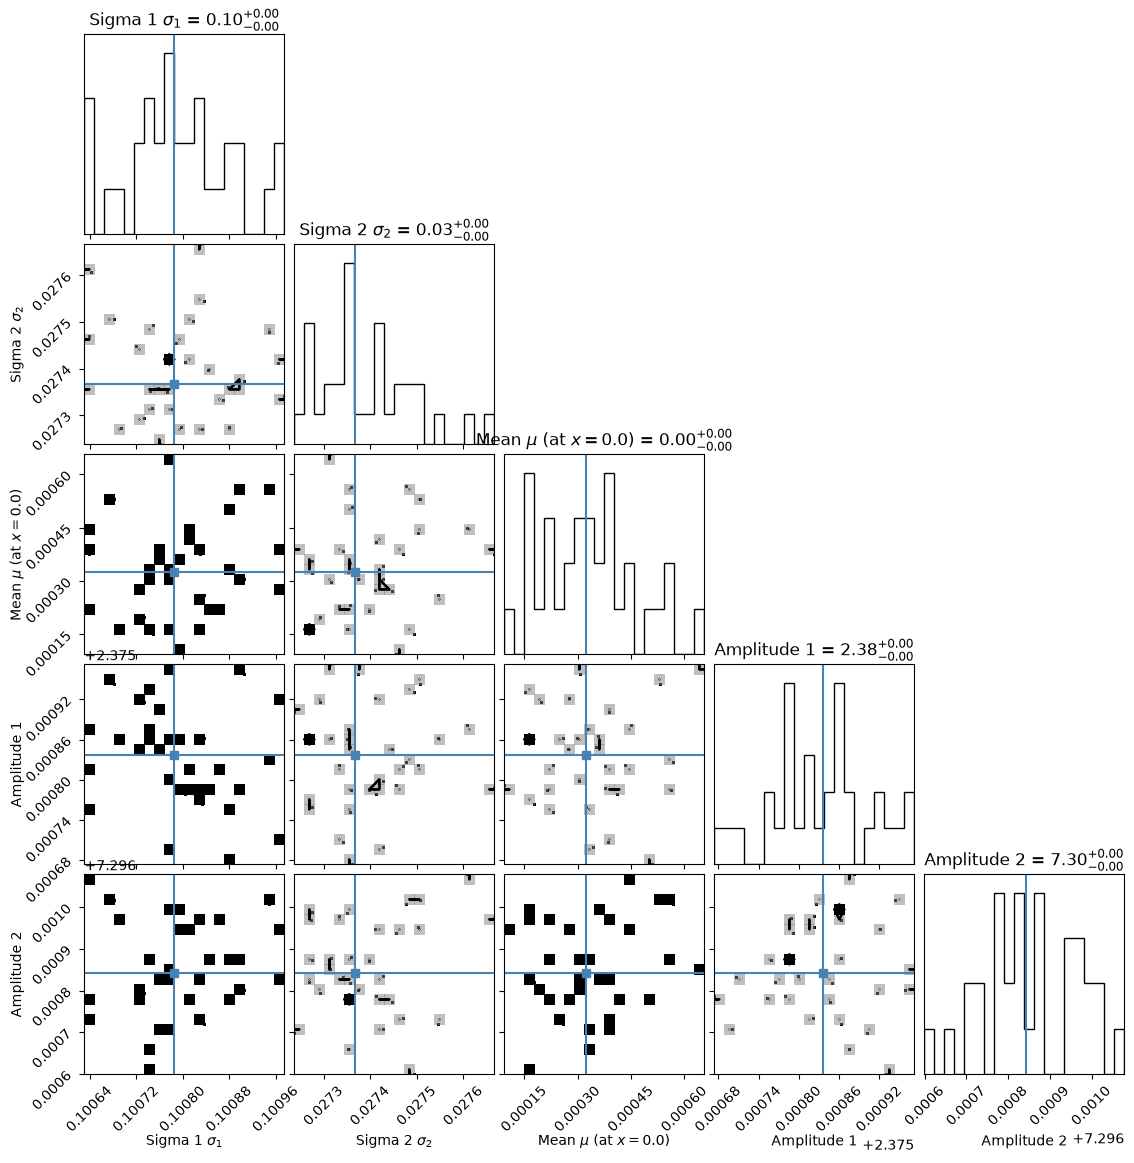

Reduced chi squared = 1.231
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m>9.5_z=9.0.h5
m bin:  [9.0, 11]
z bin:  [9.5, 10.5]
Number of gals in bin:  5
Guesses: sig = 0.096, sig = 0.030, mean = 0.007, amplitude = 2.329, amplitude = 4.667


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1926.65it/s]


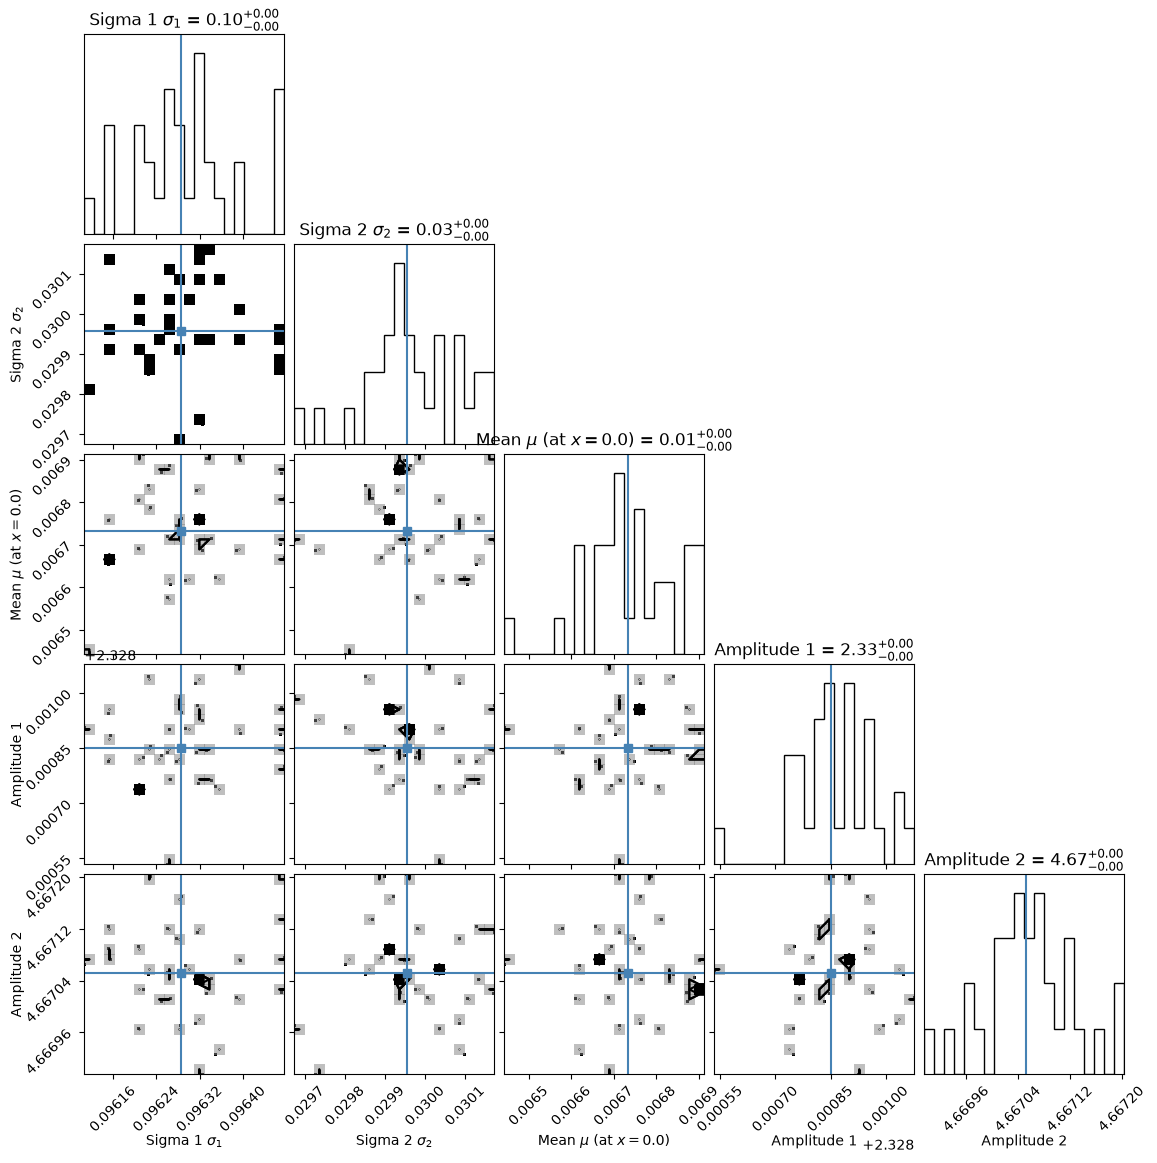

Reduced chi squared = 6.760
Posterior: -1.372 -- 0.492, length = 2500
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.069, sig = 0.020, mean = 0.007, amplitude = 4.478, amplitude = 5.007


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1901.47it/s]


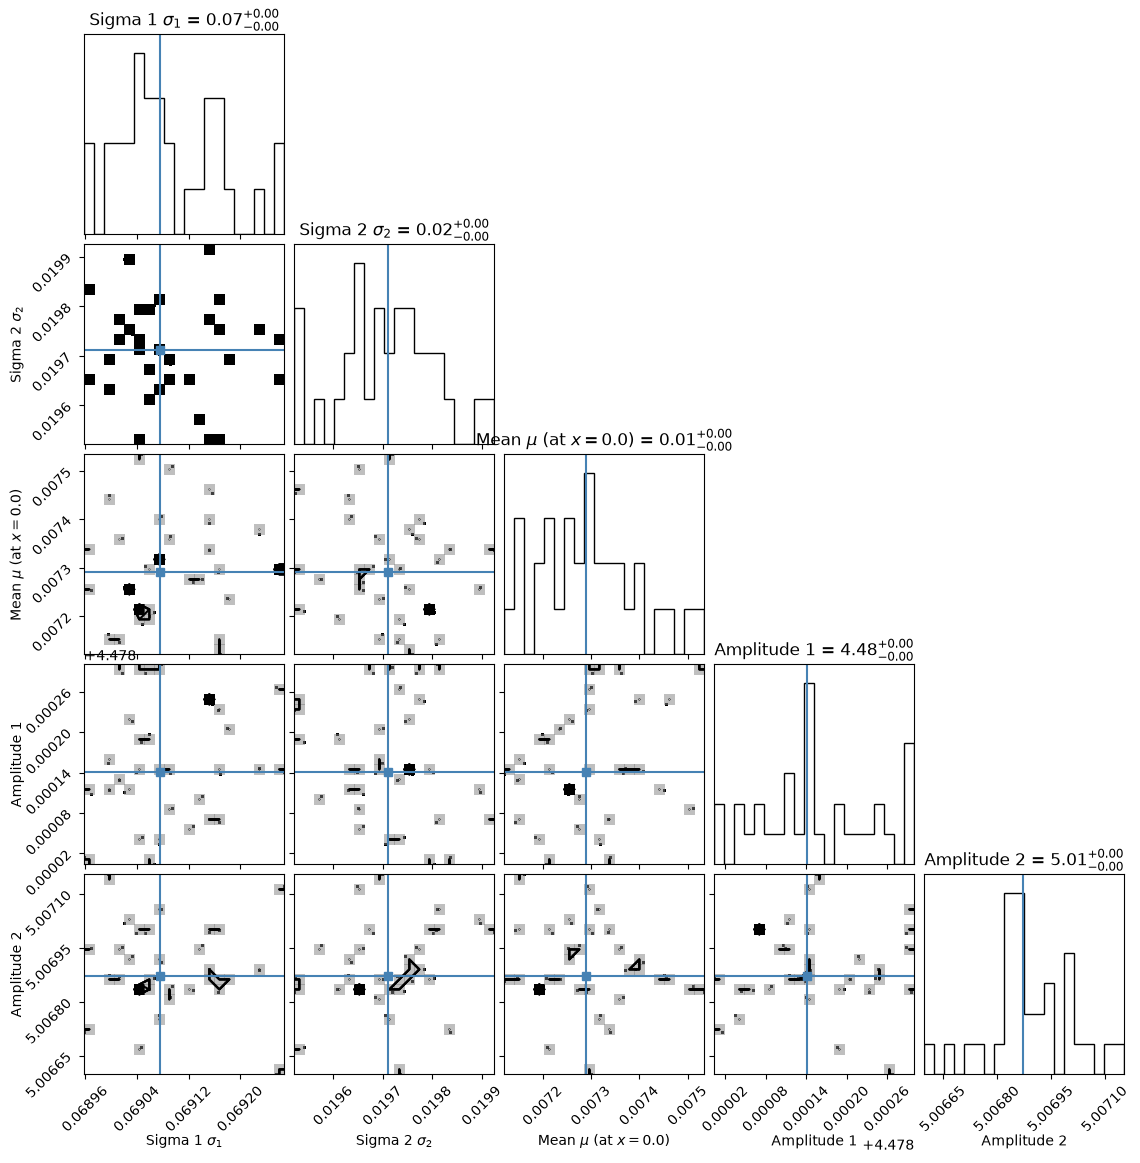

Reduced chi squared = 0.971
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m>9.5_z=10.0.h5
m bin:  [9.0, 11]
z bin:  [10.5, 11.5]
Number of gals in bin:  14
Guesses: sig = 0.026, sig = 0.154, mean = -0.000, amplitude = 2.934, amplitude = 1.960


100%|██████████| 5000/5000 [00:06<00:00, 762.66it/s]


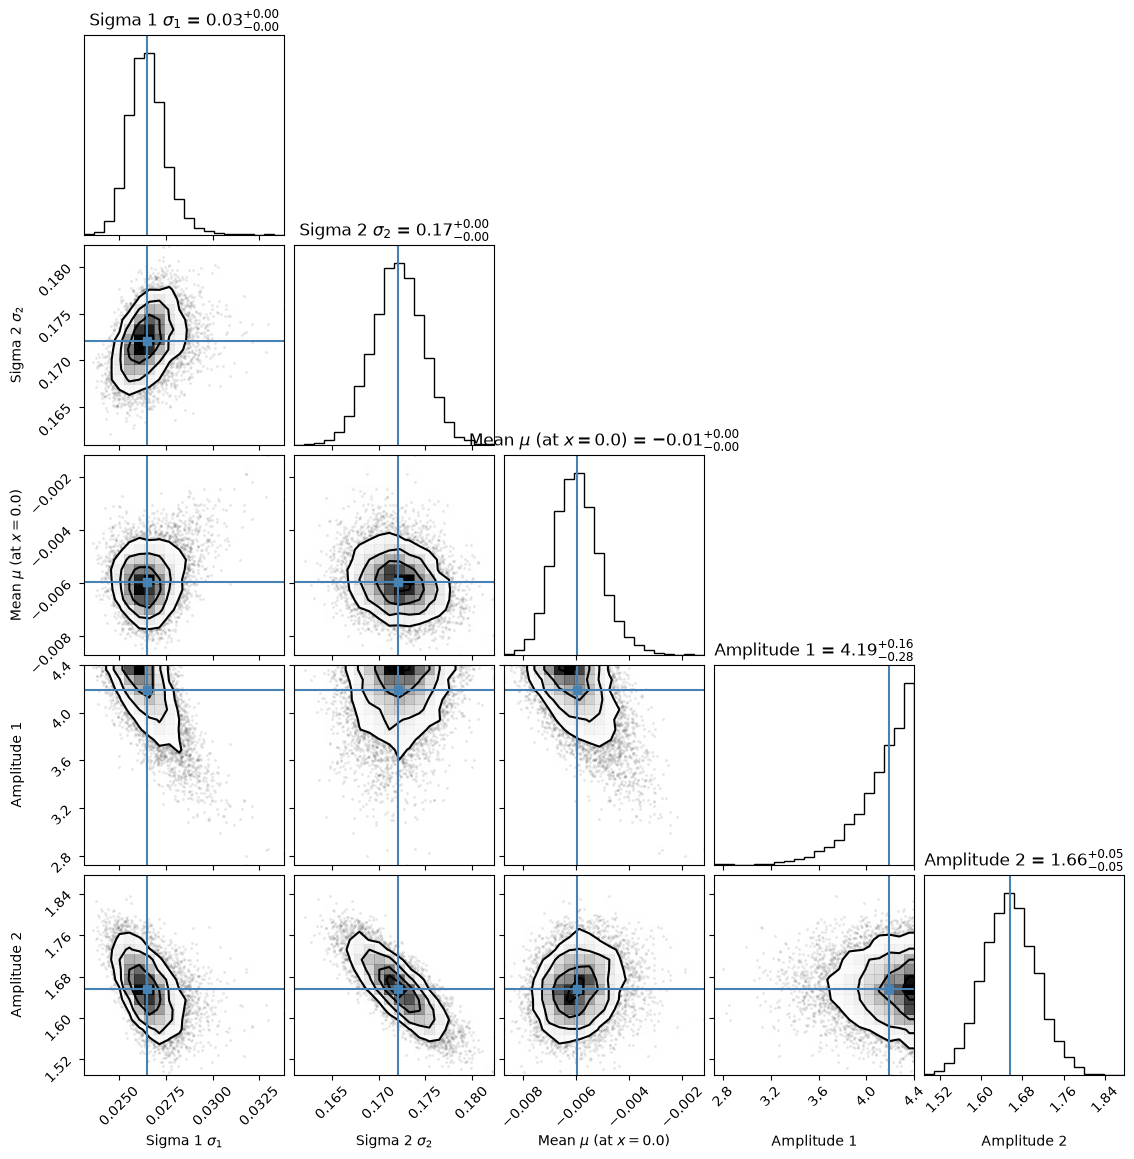

Reduced chi squared = 10.517
Posterior: -3.048 -- 1.282, length = 7000
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.175, sig = 0.044, mean = 0.015, amplitude = 1.550, amplitude = 2.623


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2333.10it/s]


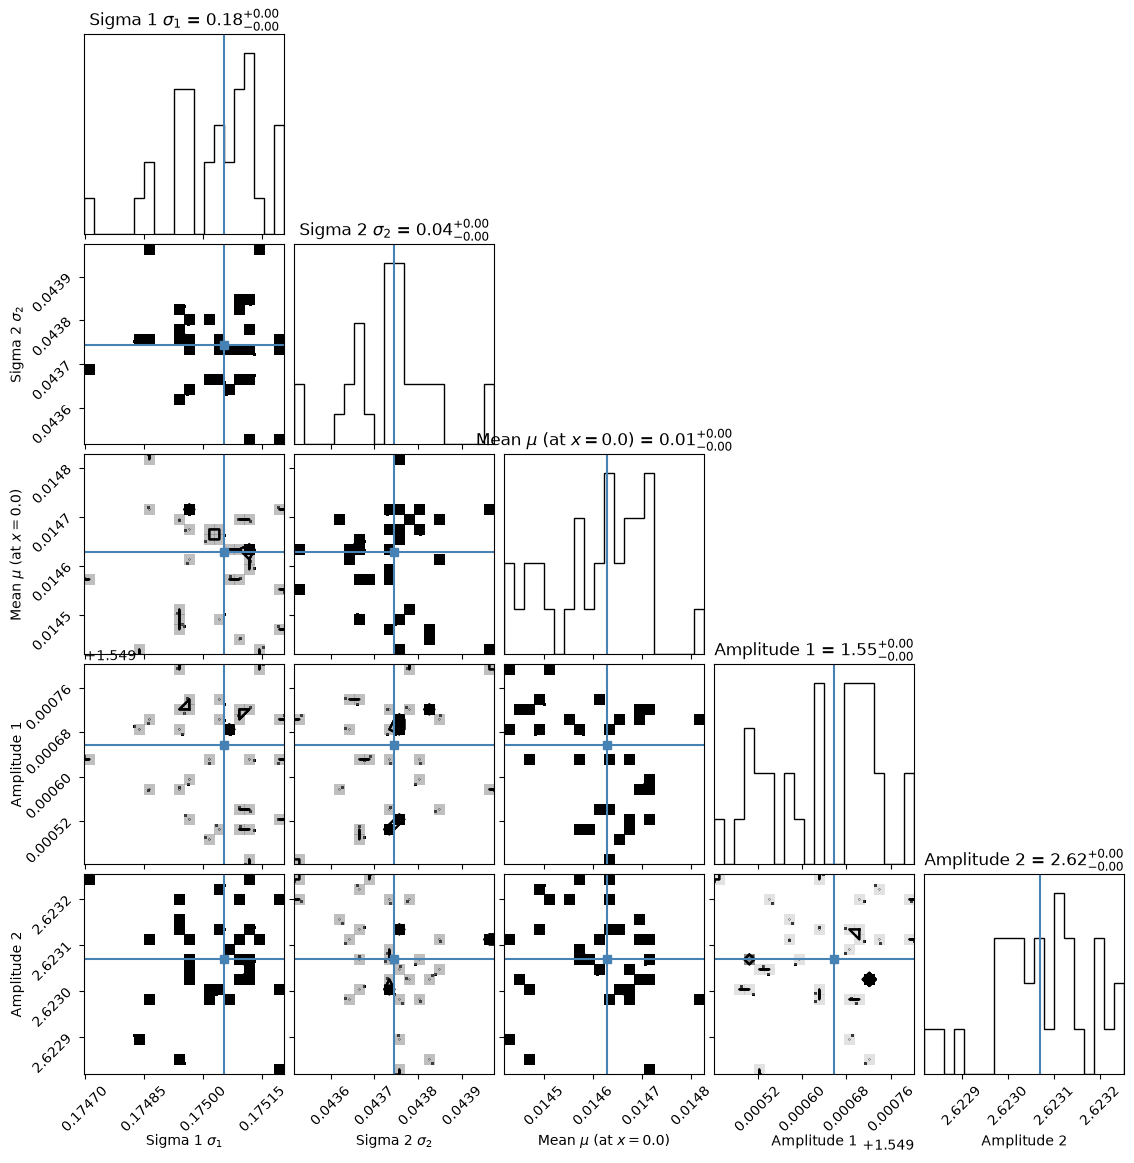

Reduced chi squared = 9.371
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m>9.5_z=11.0.h5
m bin:  [9.0, 11]
z bin:  [11.5, 13.5]
Number of gals in bin:  15
Guesses: sig = 0.143, sig = 0.516, mean = 0.037, amplitude = 1.272, amplitude = 0.320


100%|██████████| 5000/5000 [00:07<00:00, 695.17it/s]


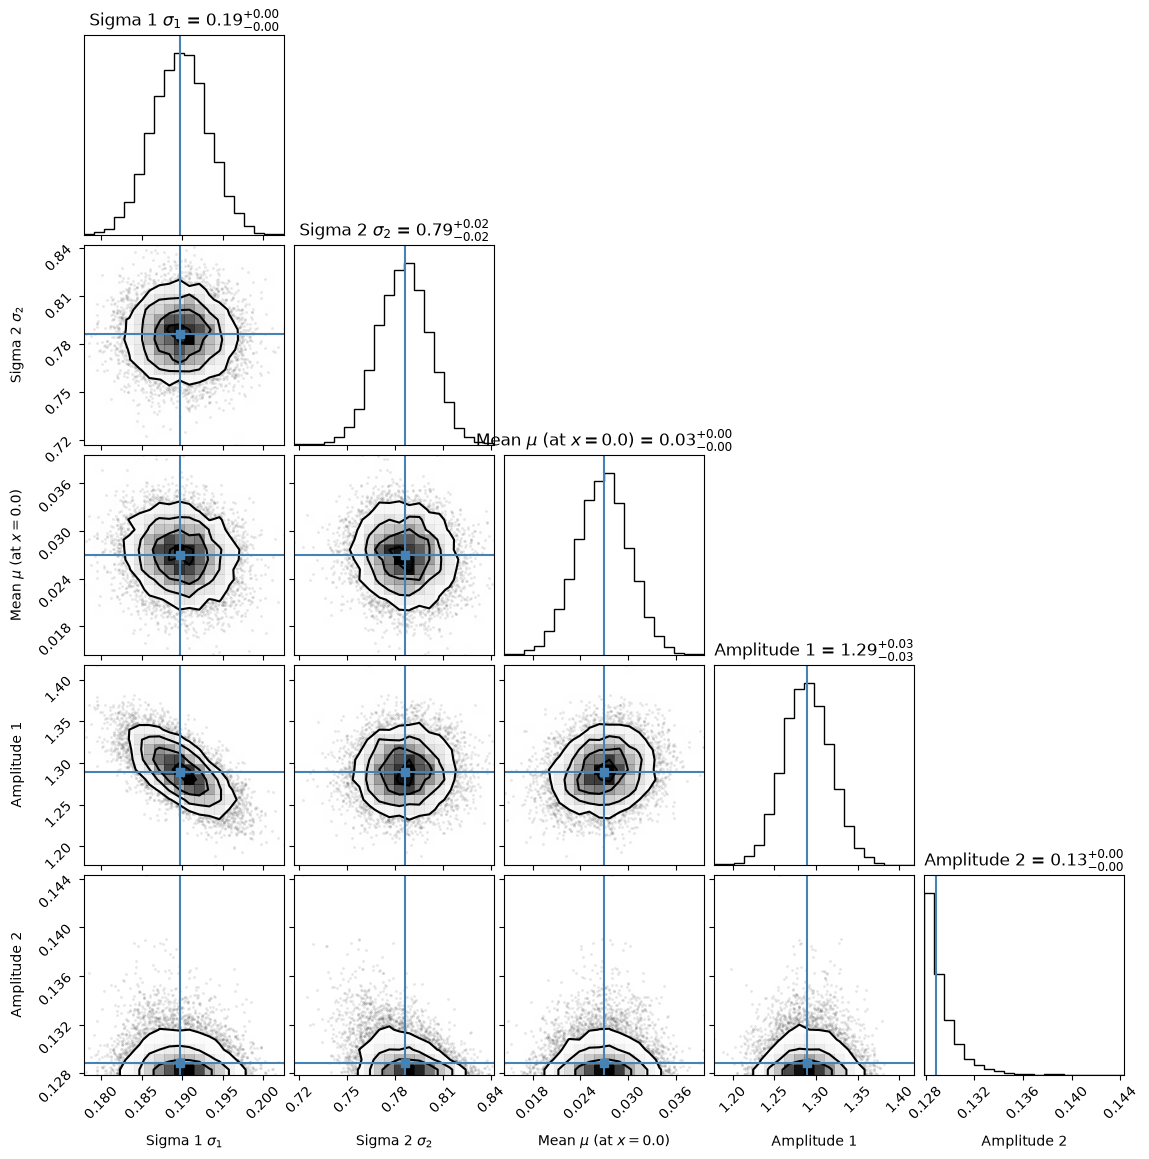

Reduced chi squared = 24.004
Posterior: -6.525 -- 2.969, length = 7500
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.423, sig = 0.121, mean = 0.038, amplitude = 0.443, amplitude = 1.302


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2319.03it/s]


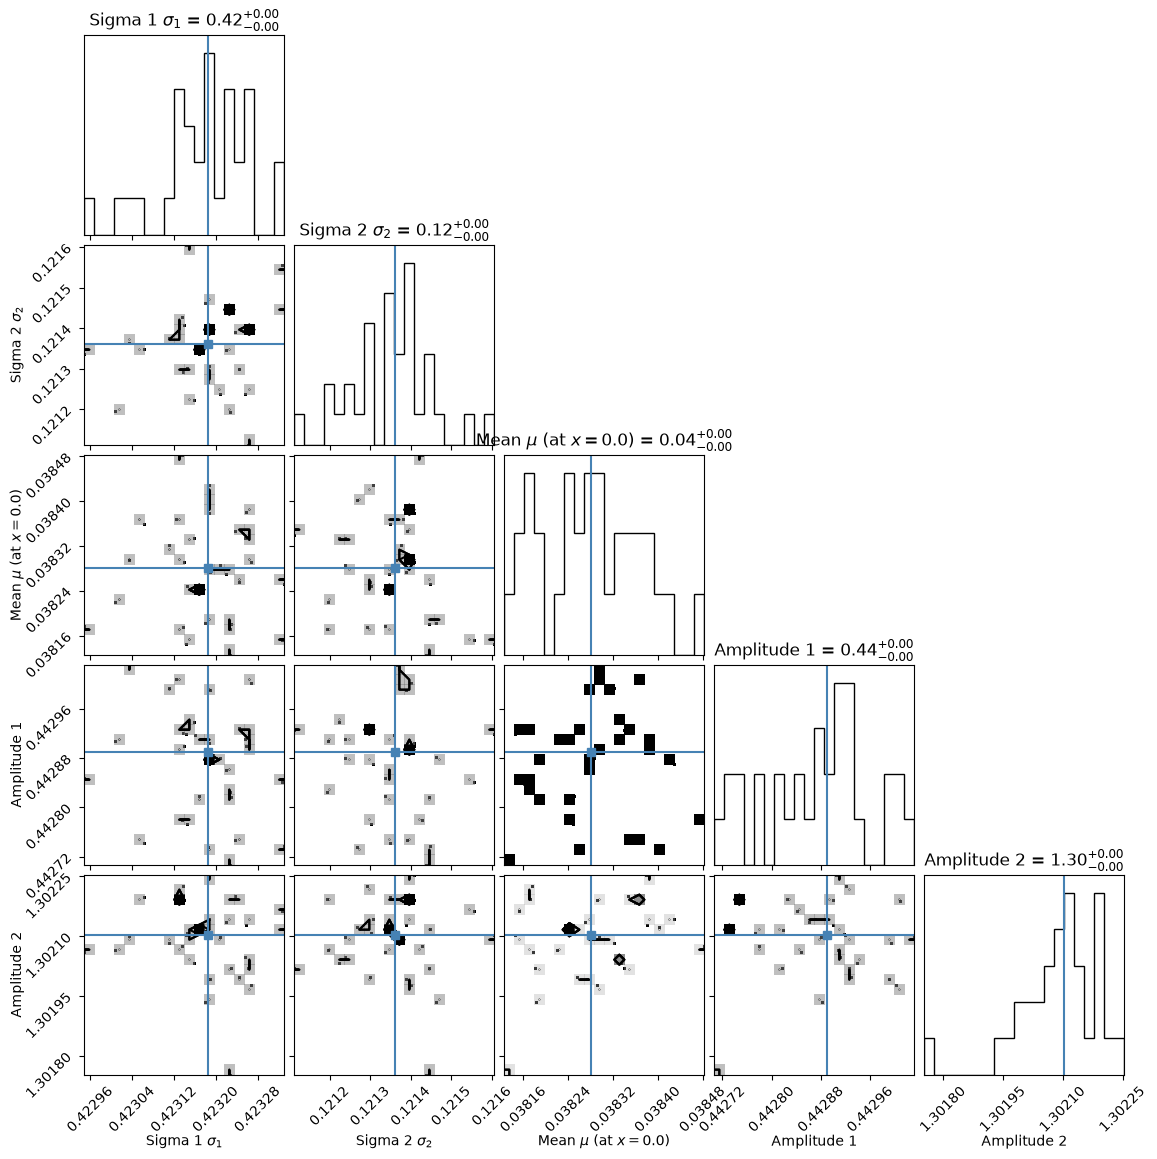

Reduced chi squared = 27.356
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m>9.5_z=12.5.h5
m bin:  [8, 9.0]
z bin:  [6.5, 7.5]
Number of gals in bin:  314
Guesses: sig = 0.645, sig = 0.228, mean = -0.018, amplitude = 0.052, amplitude = 1.569


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1800.26it/s]


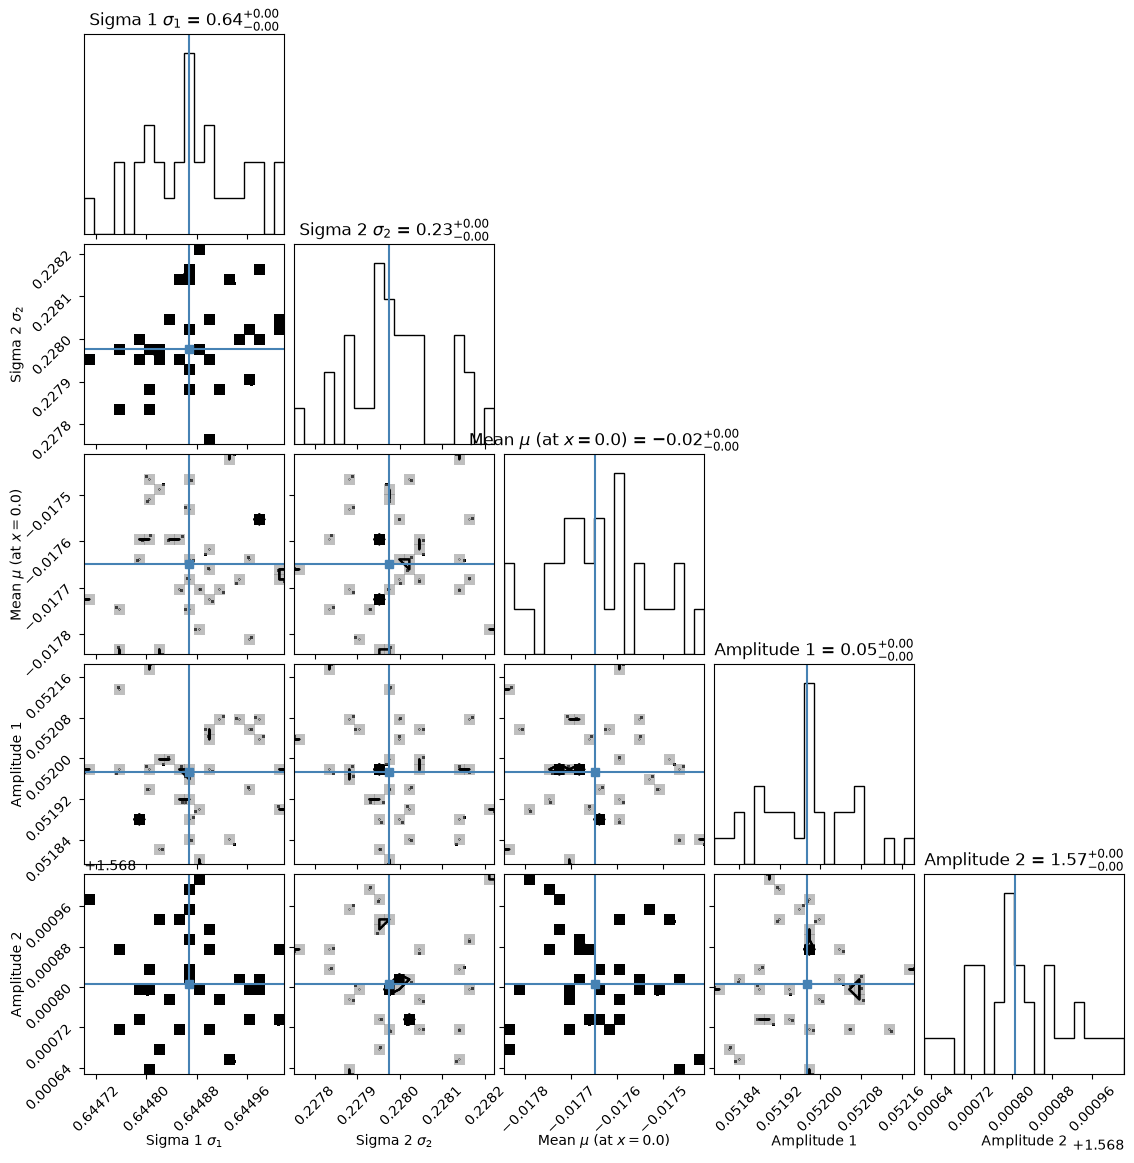

Reduced chi squared = 17.113
Posterior: -9.703 -- 13.832, length = 157000
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.075, sig = 0.243, mean = 0.002, amplitude = 1.914, amplitude = 1.009


100%|██████████| 5000/5000 [00:07<00:00, 659.32it/s]


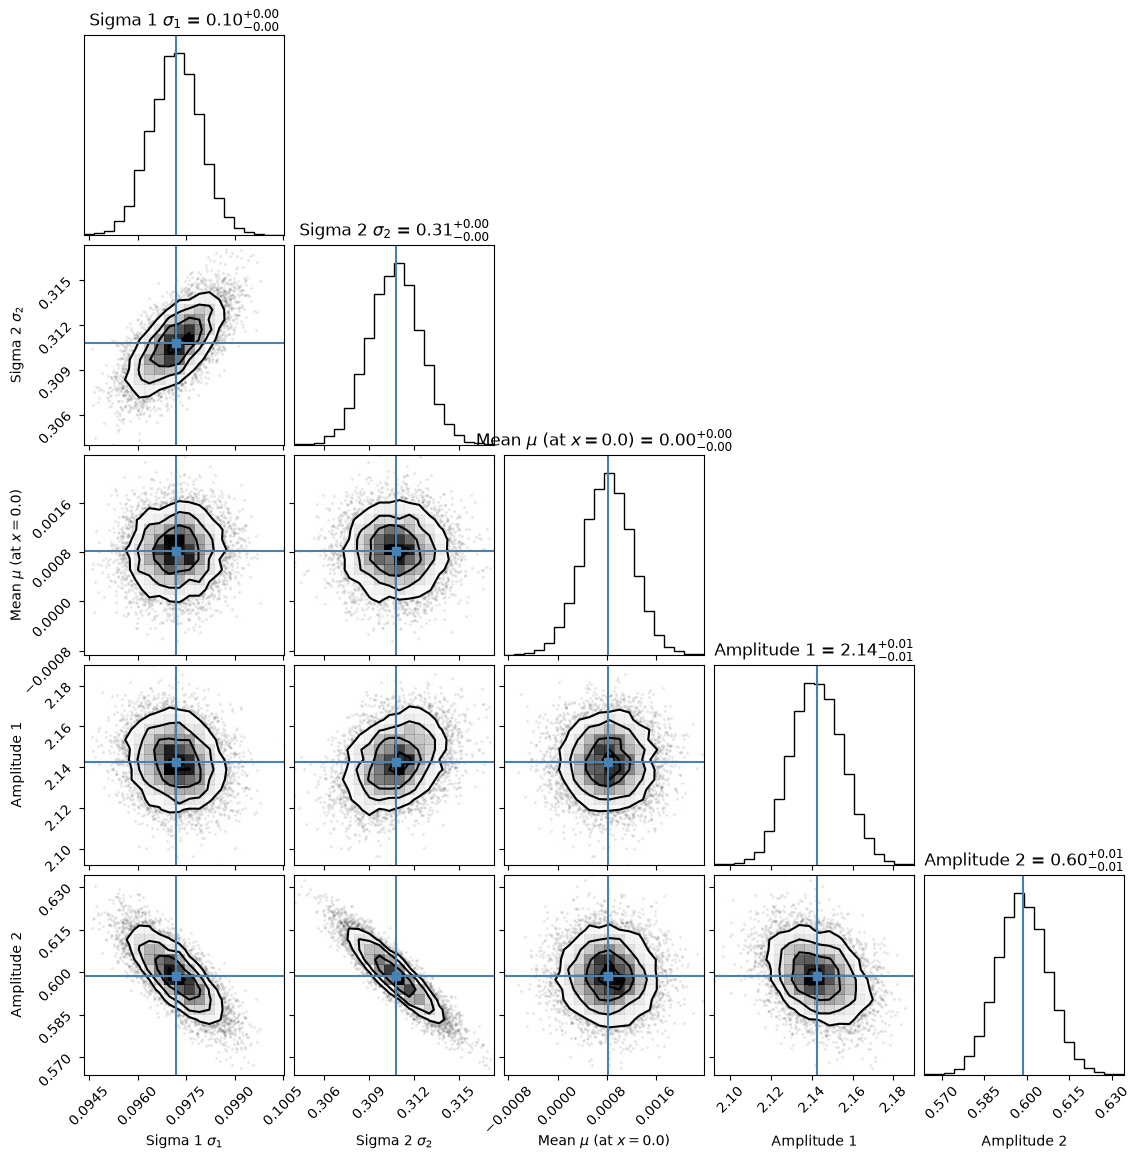

Reduced chi squared = 41.001
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m=8-9.5_z=7.0.h5
m bin:  [8, 9.0]
z bin:  [7.5, 8.5]
Number of gals in bin:  137
Guesses: sig = 0.268, sig = 0.084, mean = 0.001, amplitude = 0.834, amplitude = 1.935


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2414.90it/s]


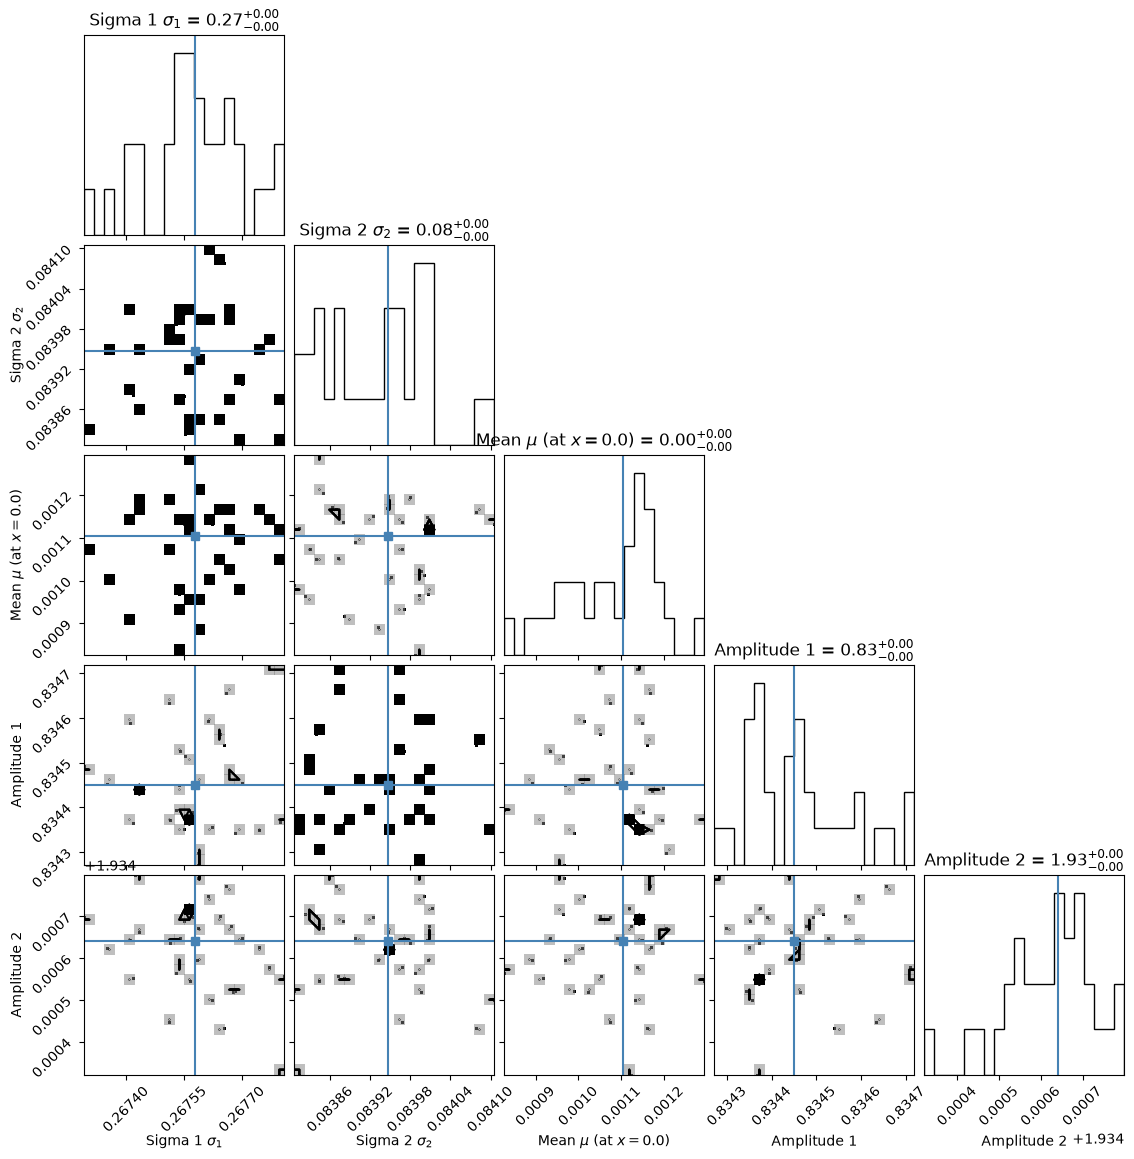

Reduced chi squared = 51.235
Posterior: -2.098 -- 2.082, length = 68500
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.068, sig = 0.214, mean = 0.000, amplitude = 1.946, amplitude = 1.310


100%|██████████| 5000/5000 [00:06<00:00, 752.04it/s]


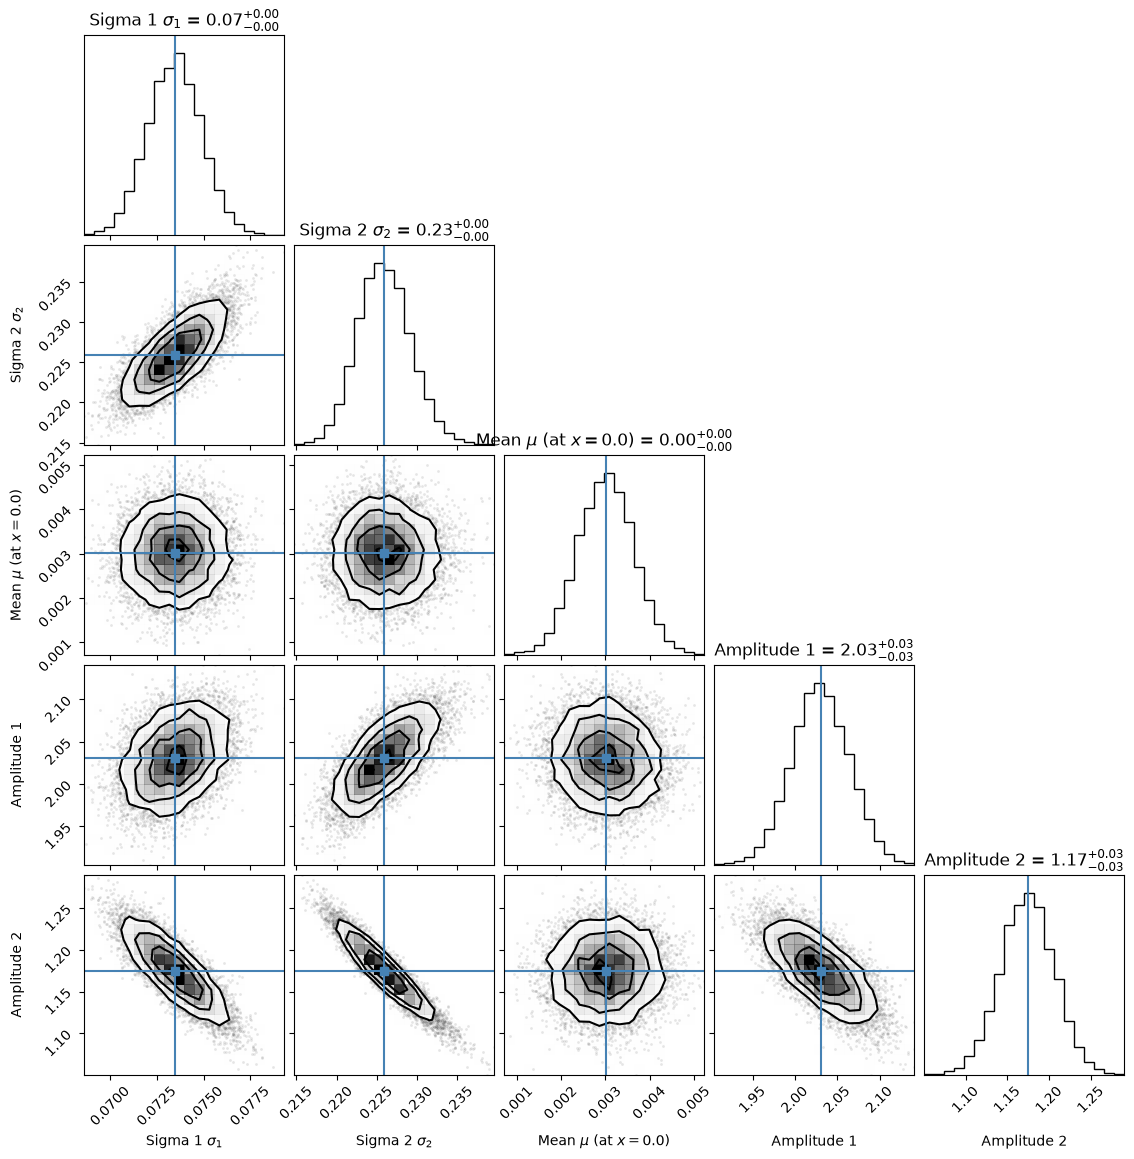

Reduced chi squared = 4.077
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m=8-9.5_z=8.0.h5
m bin:  [8, 9.0]
z bin:  [8.5, 9.5]
Number of gals in bin:  47
Guesses: sig = 0.106, sig = 0.377, mean = 0.004, amplitude = 1.804, amplitude = 0.531


100%|██████████| 5000/5000 [00:08<00:00, 610.56it/s]


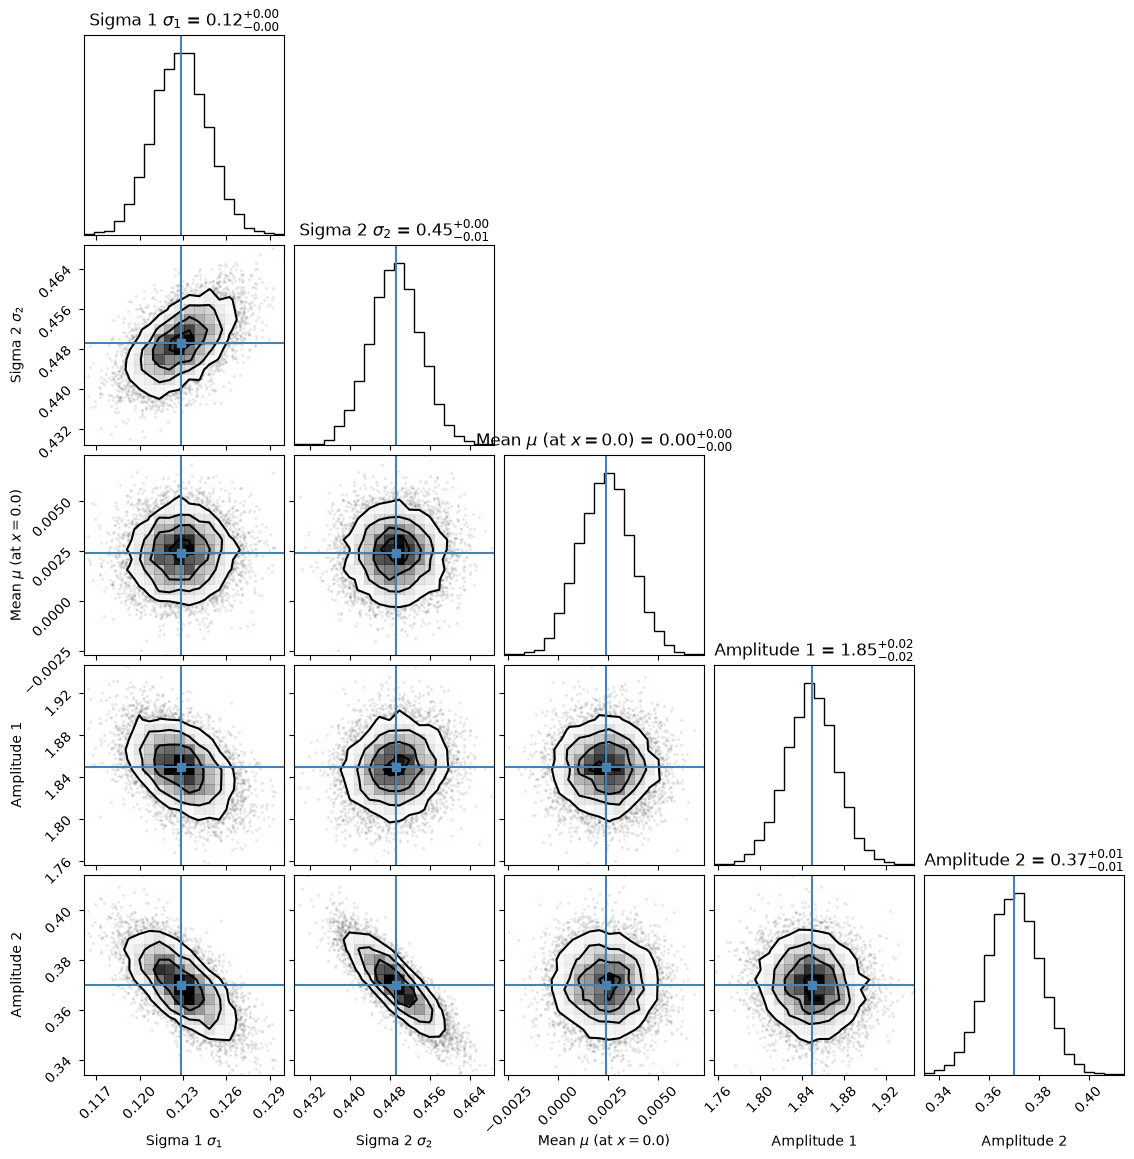

Reduced chi squared = 7.195
Posterior: -1.801 -- 4.930, length = 23500
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.369, sig = 0.101, mean = 0.001, amplitude = 0.546, amplitude = 1.885


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2051.60it/s]


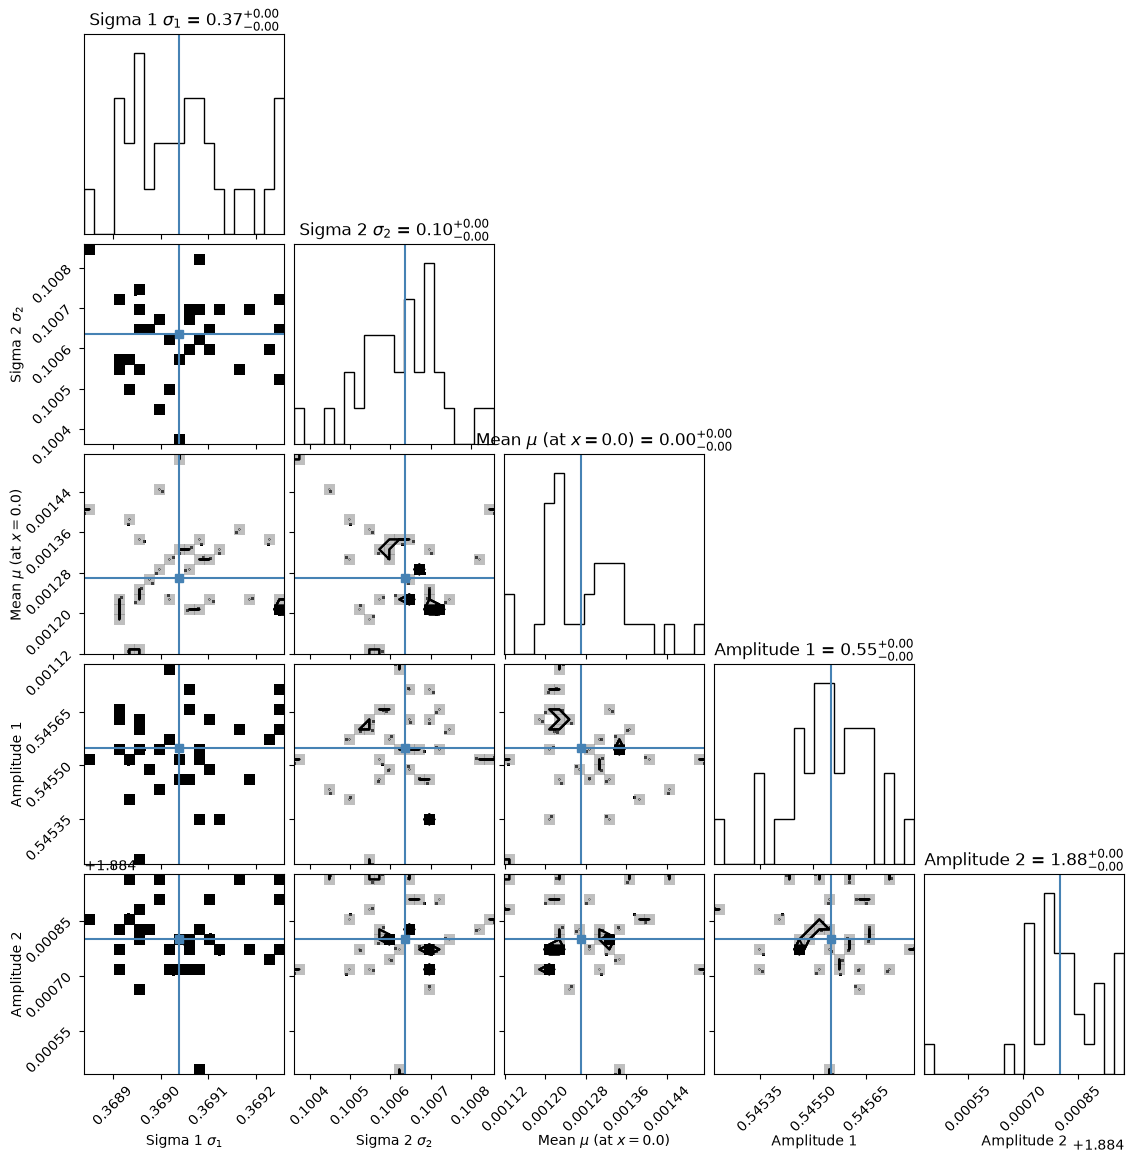

Reduced chi squared = 13.010
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m=8-9.5_z=9.0.h5
m bin:  [8, 9.0]
z bin:  [9.5, 10.5]
Number of gals in bin:  47
Guesses: sig = 0.121, sig = 0.428, mean = 0.019, amplitude = 1.358, amplitude = 0.532


100%|██████████| 5000/5000 [00:08<00:00, 608.65it/s]


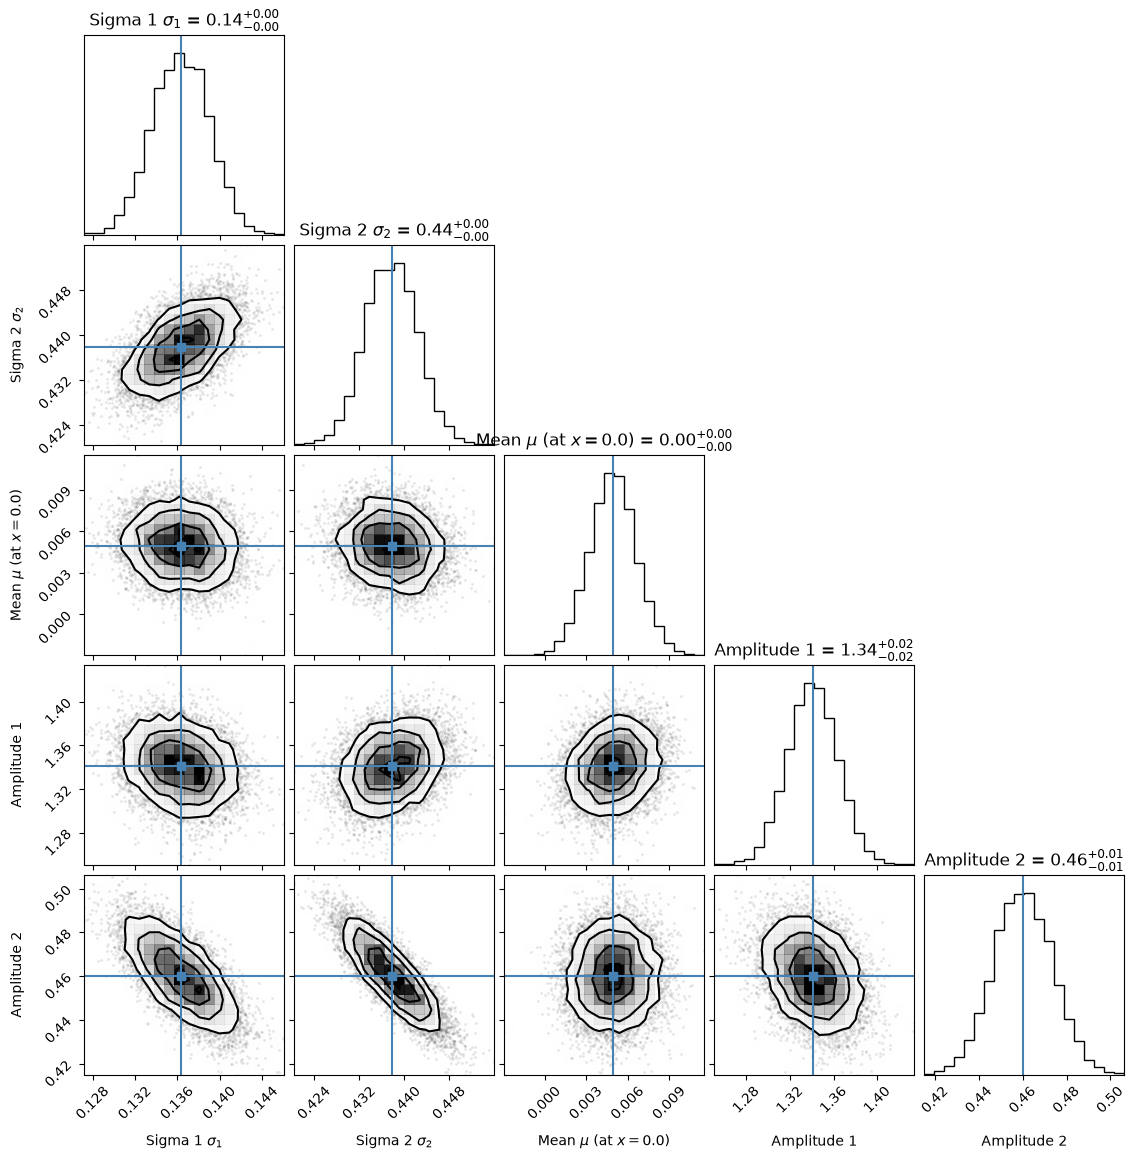

Reduced chi squared = 19.315
Posterior: -2.056 -- 1.993, length = 23500
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m=8-9.5_z=10.0.h5
m bin:  [8, 9.0]
z bin:  [10.5, 11.5]
Number of gals in bin:  45
Guesses: sig = 0.543, sig = 0.109, mean = 0.036, amplitude = 0.497, amplitude = 1.085


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2116.62it/s]


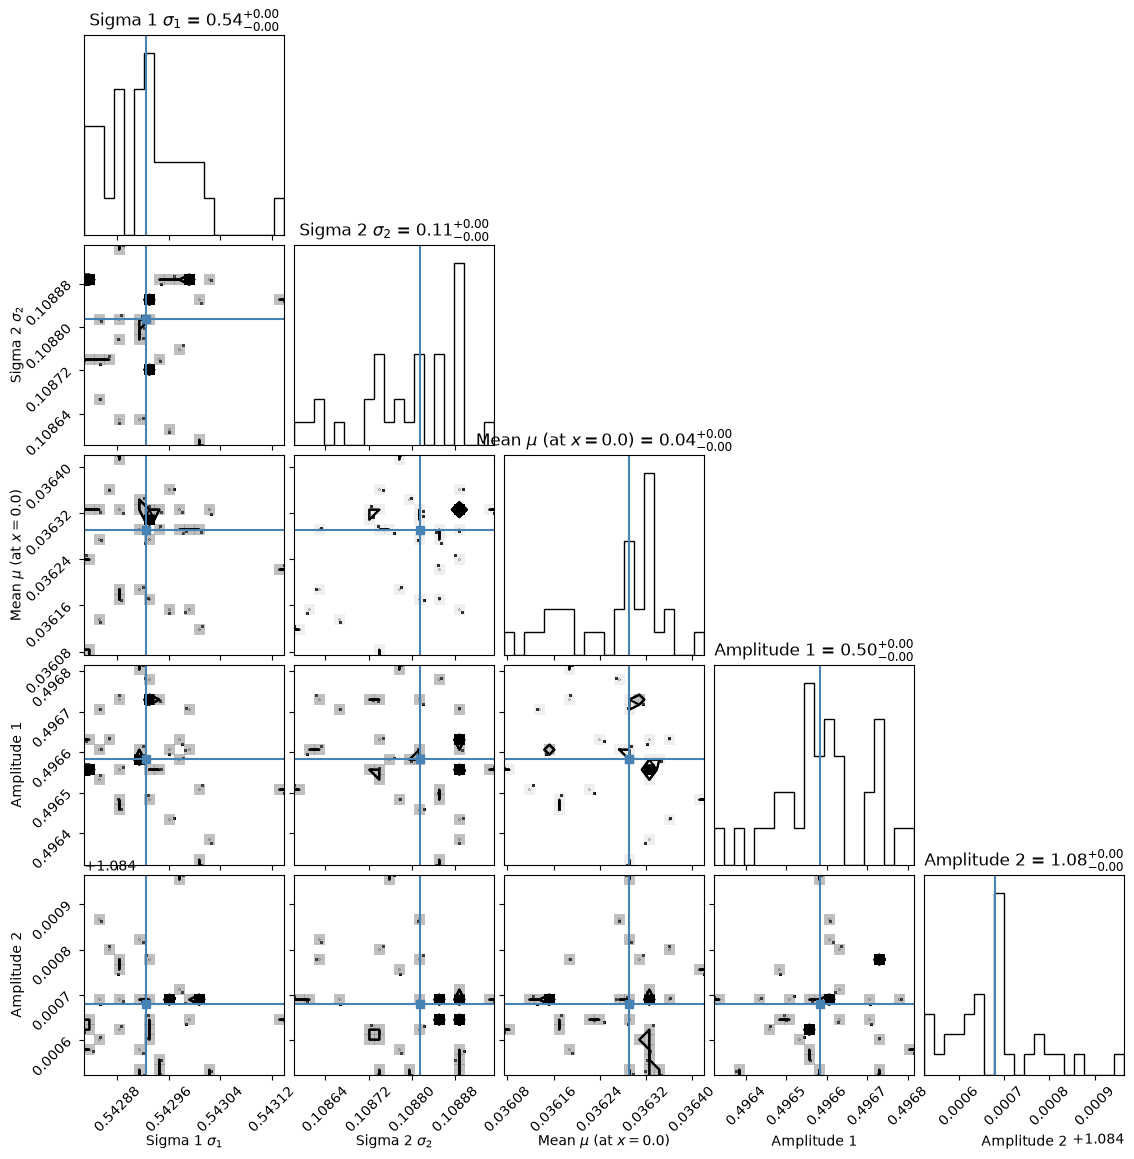

Reduced chi squared = 94.263
Posterior: -2.181 -- 1.427, length = 22500
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.387, sig = 0.090, mean = 0.037, amplitude = 0.877, amplitude = 1.258


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2416.83it/s]


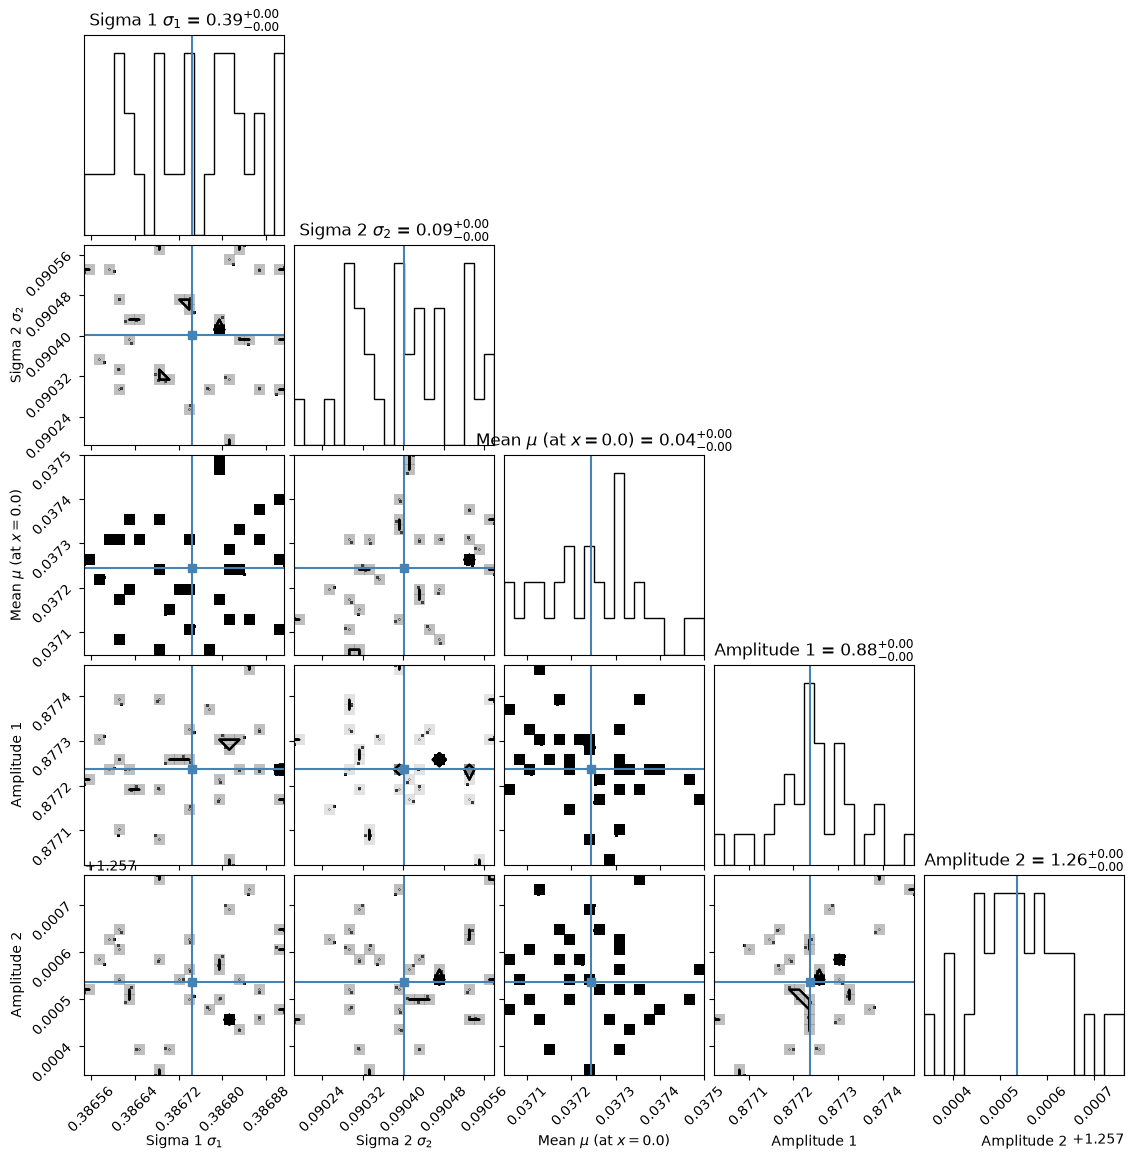

Reduced chi squared = 3.894
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m=8-9.5_z=11.0.h5
m bin:  [8, 9.0]
z bin:  [11.5, 13.5]
Number of gals in bin:  42
Guesses: sig = 0.788, sig = 0.121, mean = 0.031, amplitude = 0.298, amplitude = 1.338


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2169.73it/s]


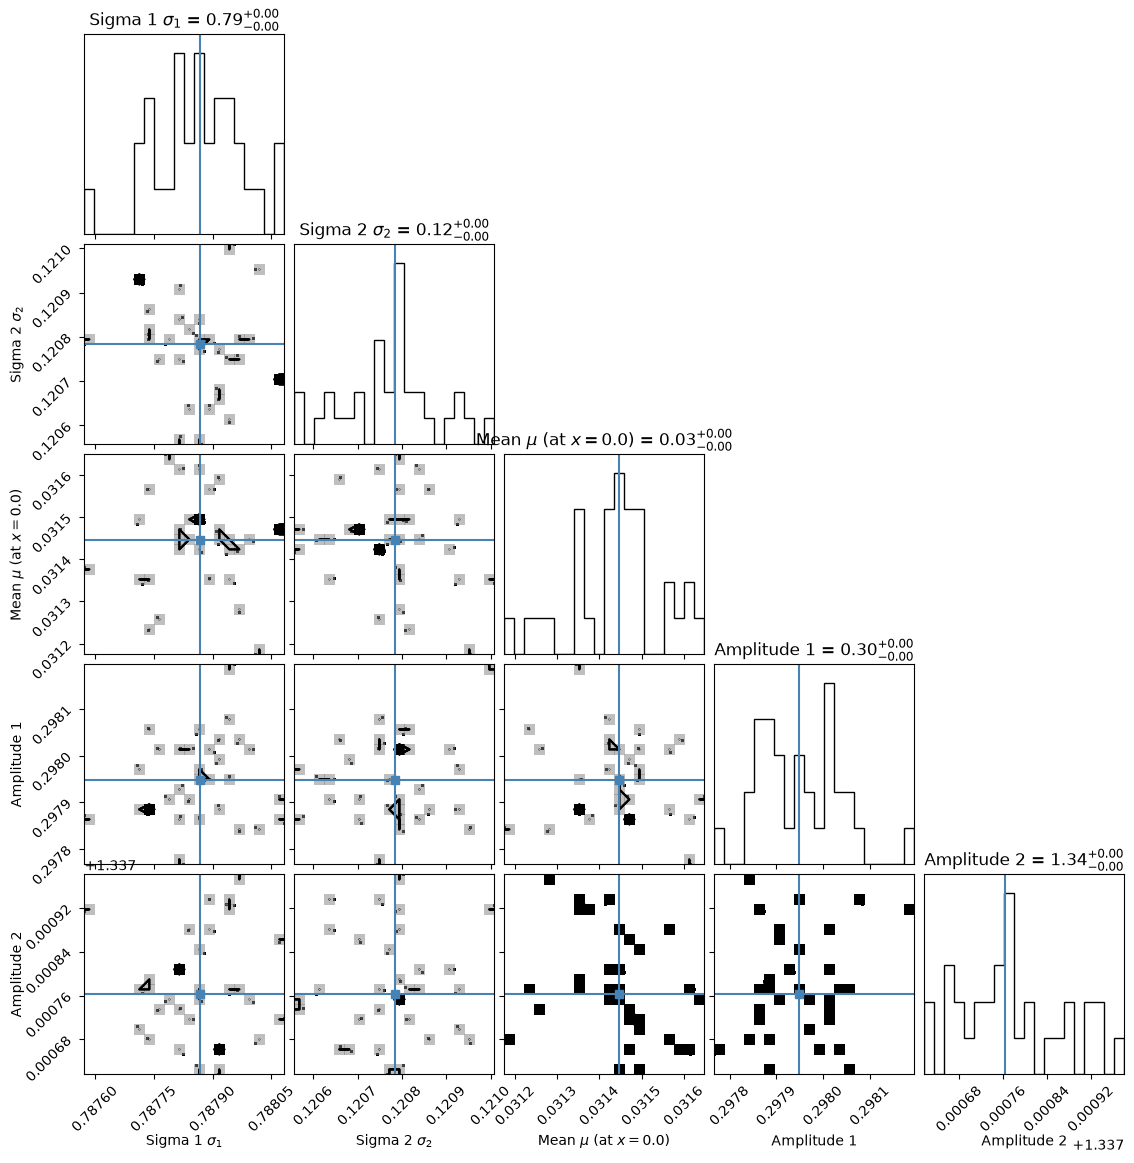

Reduced chi squared = 38.844
Posterior: -3.456 -- 3.706, length = 21000
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.083, sig = 0.346, mean = 0.025, amplitude = 1.668, amplitude = 0.815


100%|██████████| 5000/5000 [00:07<00:00, 657.71it/s]


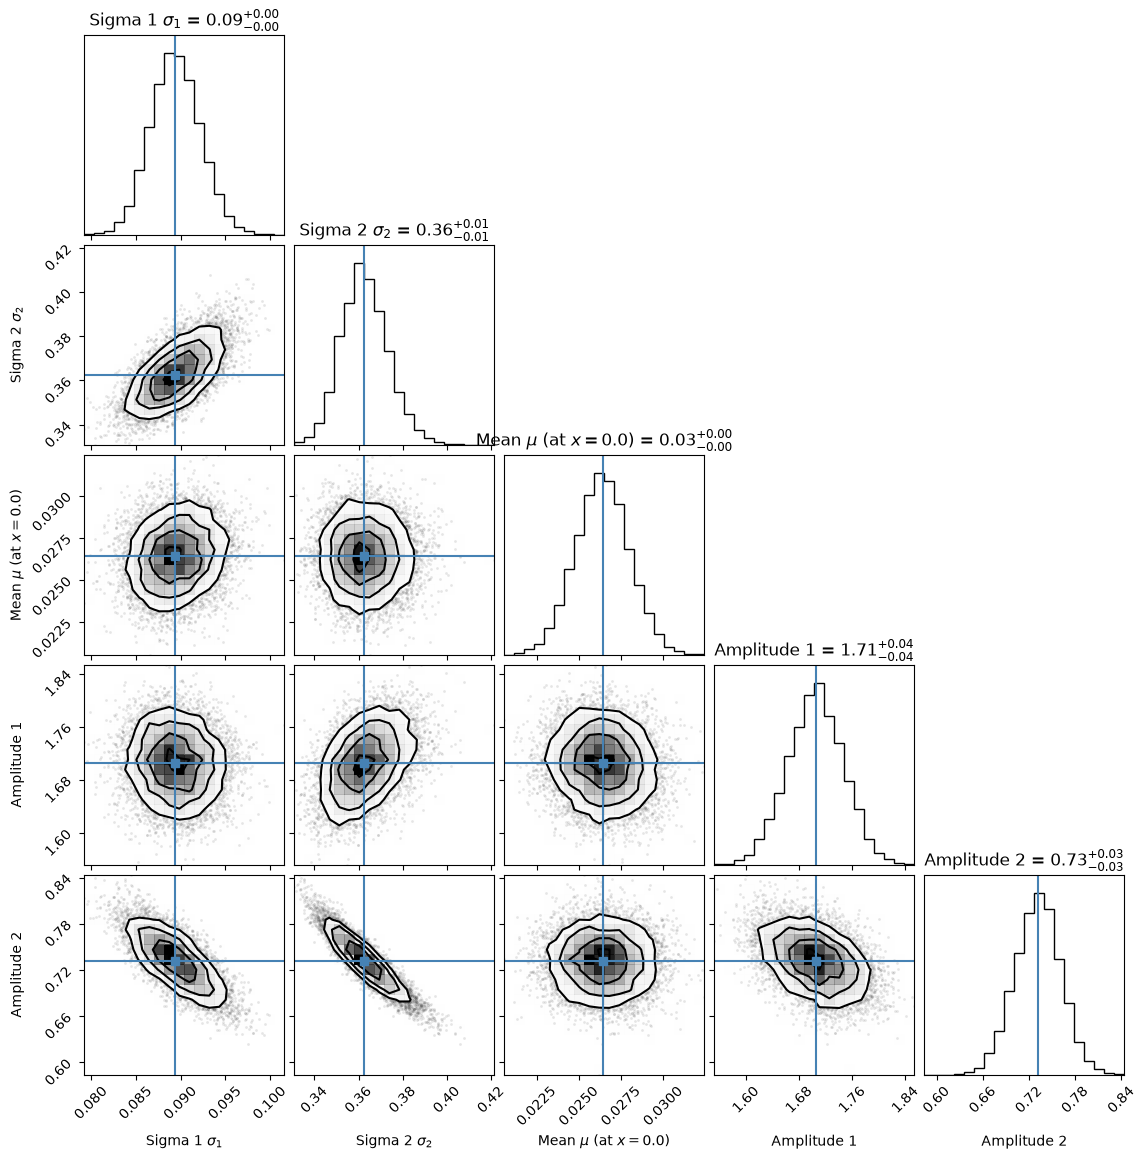

Reduced chi squared = 5.698
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m=8-9.5_z=12.5.h5
m bin:  [5, 8]
z bin:  [6.5, 7.5]
Number of gals in bin:  958
Guesses: sig = 0.250, sig = 0.084, mean = -0.014, amplitude = 0.963, amplitude = 1.814


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 1985.75it/s]


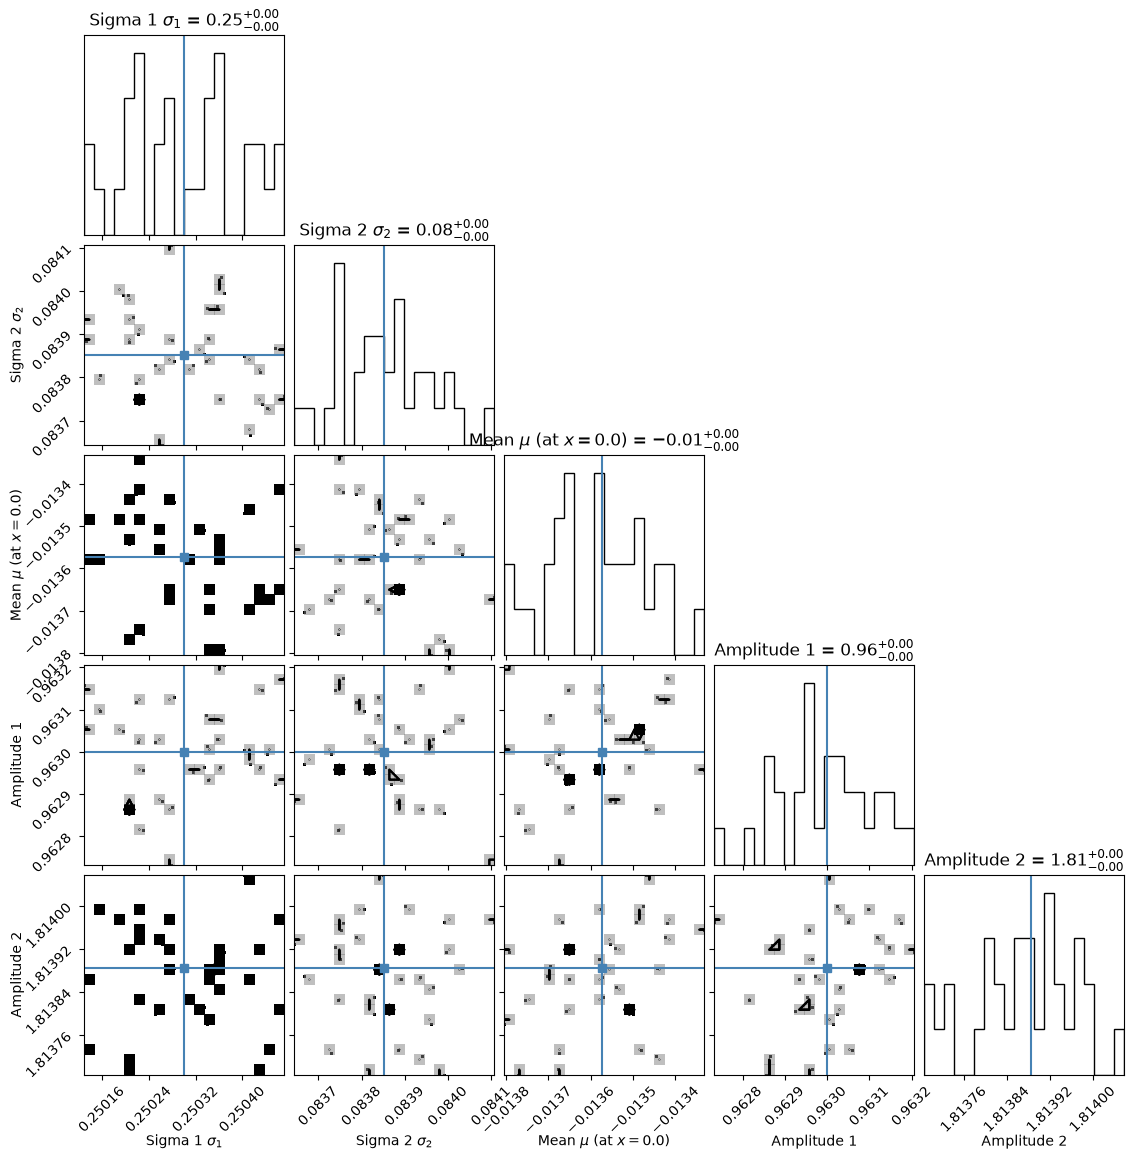

Reduced chi squared = 496.446
Posterior: -2.055 -- 3.330, length = 479000
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.063, sig = 0.210, mean = -0.015, amplitude = 1.907, amplitude = 1.389


100%|██████████| 5000/5000 [00:07<00:00, 689.03it/s]


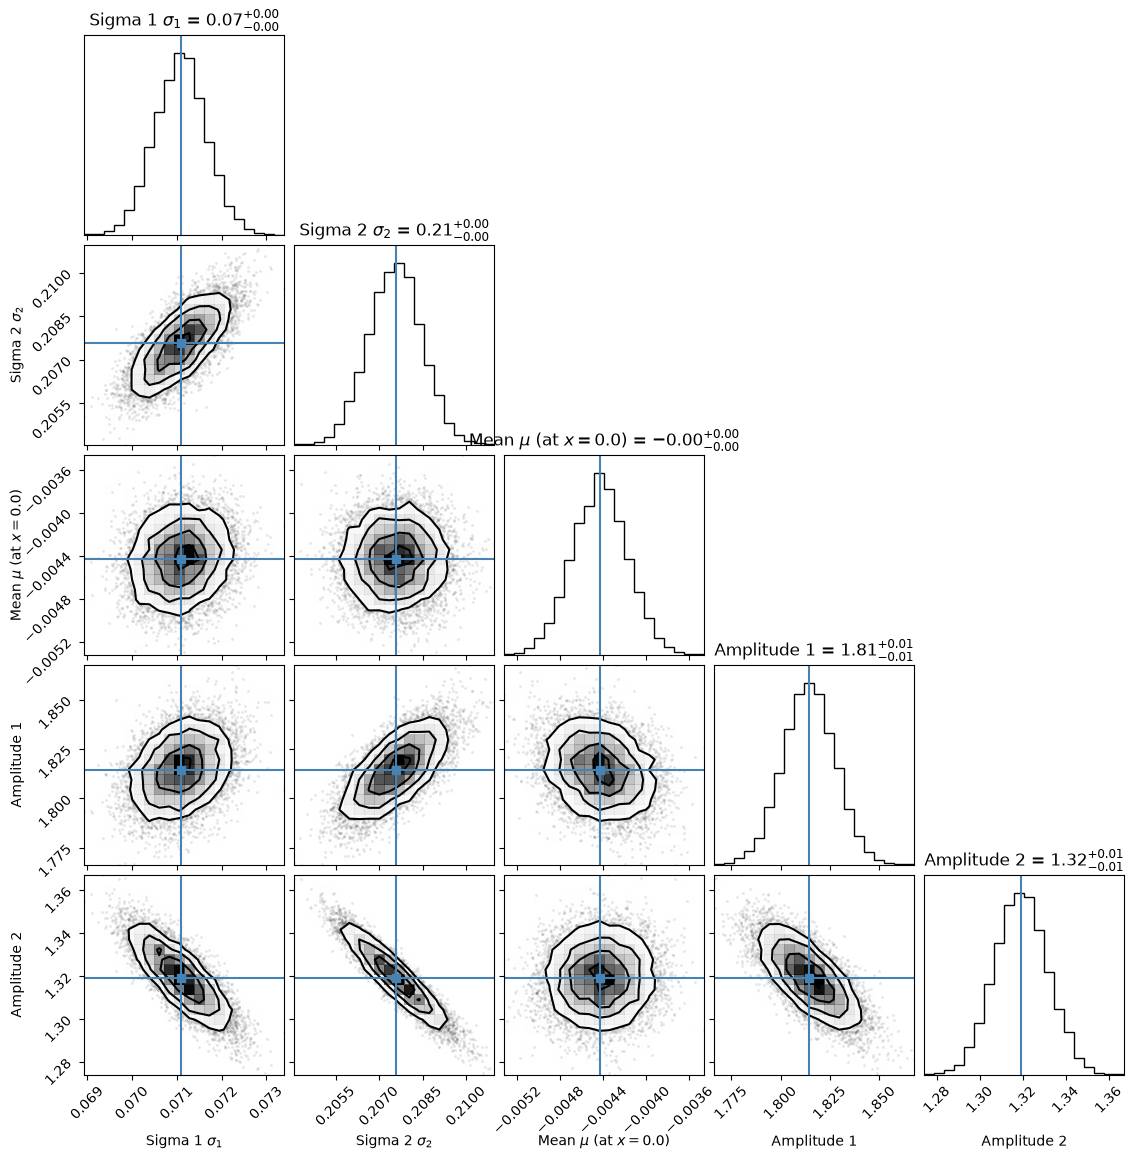

Reduced chi squared = 197.990
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m<8_z=7.0.h5
m bin:  [5, 8]
z bin:  [7.5, 8.5]
Number of gals in bin:  406
Guesses: sig = 0.264, sig = 0.077, mean = -0.015, amplitude = 0.953, amplitude = 1.740


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2380.71it/s]


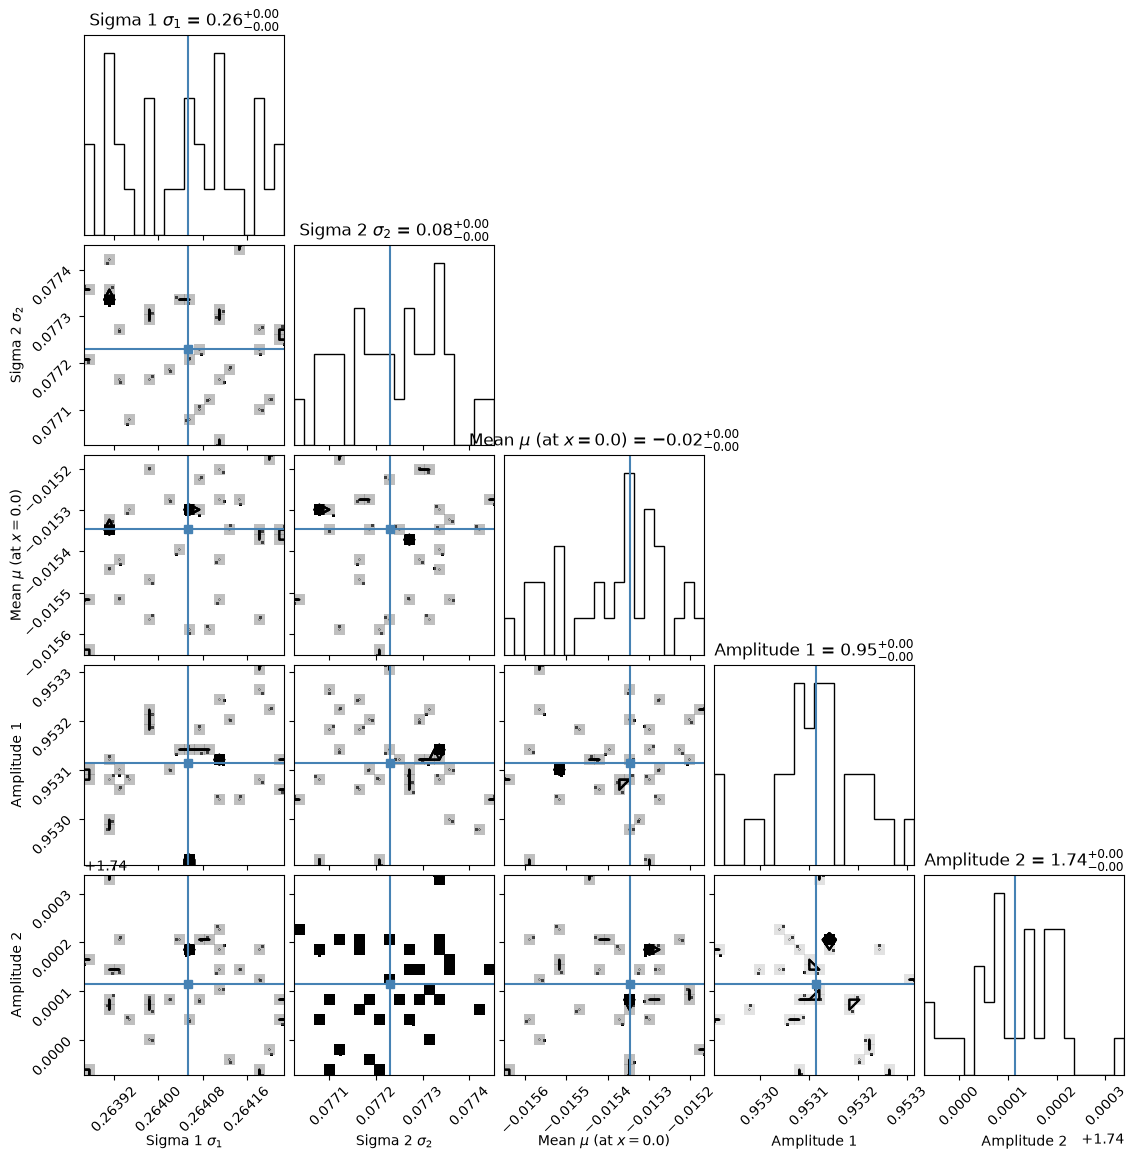

Reduced chi squared = 301.410
Posterior: -1.672 -- 2.609, length = 203000
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.056, sig = 0.207, mean = -0.020, amplitude = 1.810, amplitude = 1.526


100%|██████████| 5000/5000 [00:07<00:00, 702.62it/s]


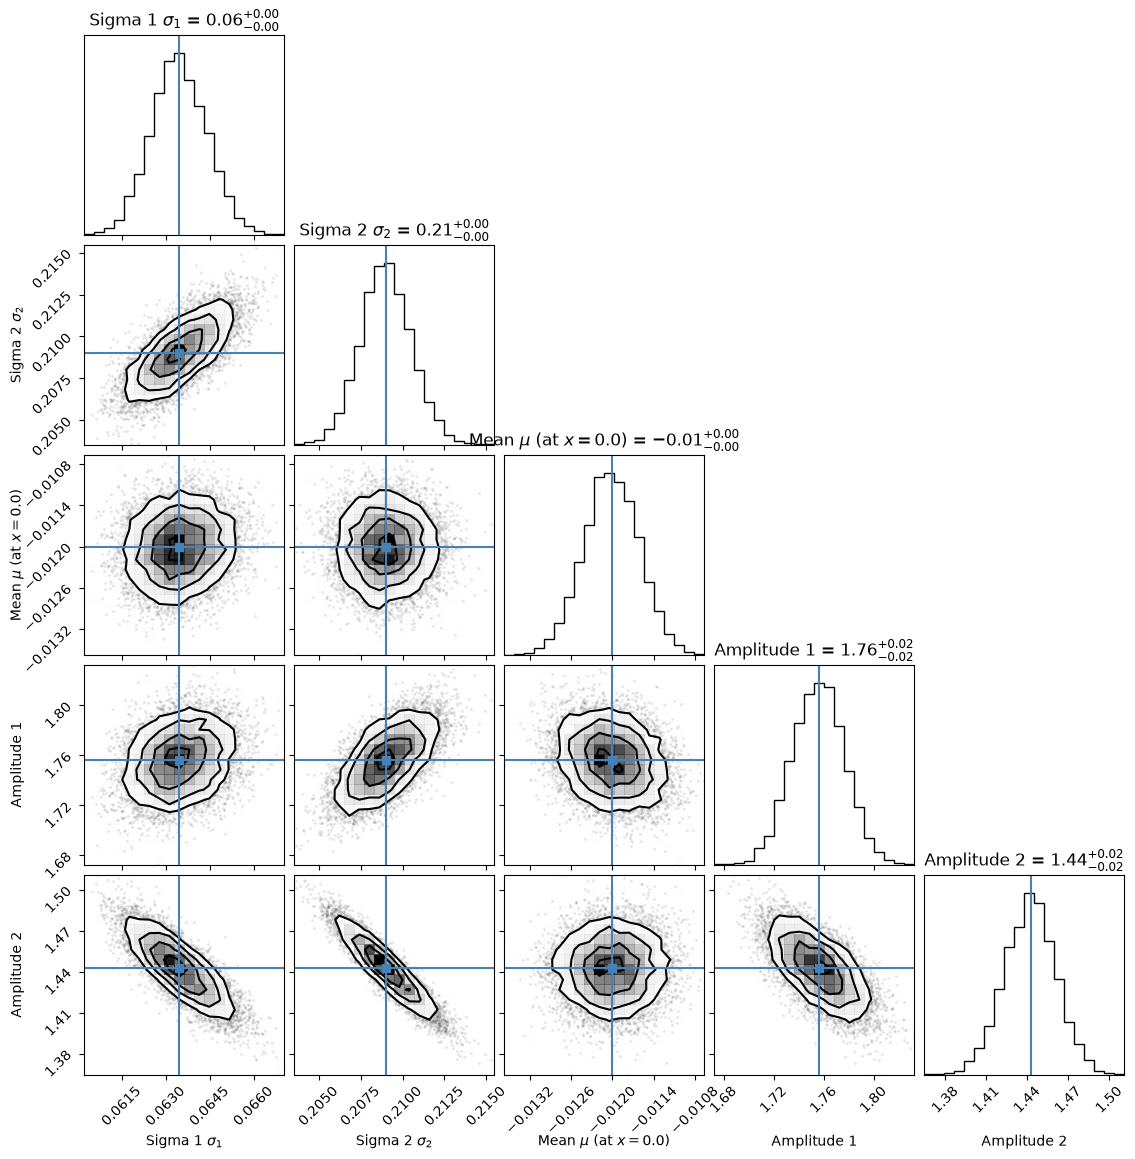

Reduced chi squared = 54.584
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m<8_z=8.0.h5
m bin:  [5, 8]
z bin:  [8.5, 9.5]
Number of gals in bin:  173
Guesses: sig = 0.312, sig = 0.083, mean = -0.021, amplitude = 0.759, amplitude = 1.808


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2346.30it/s]


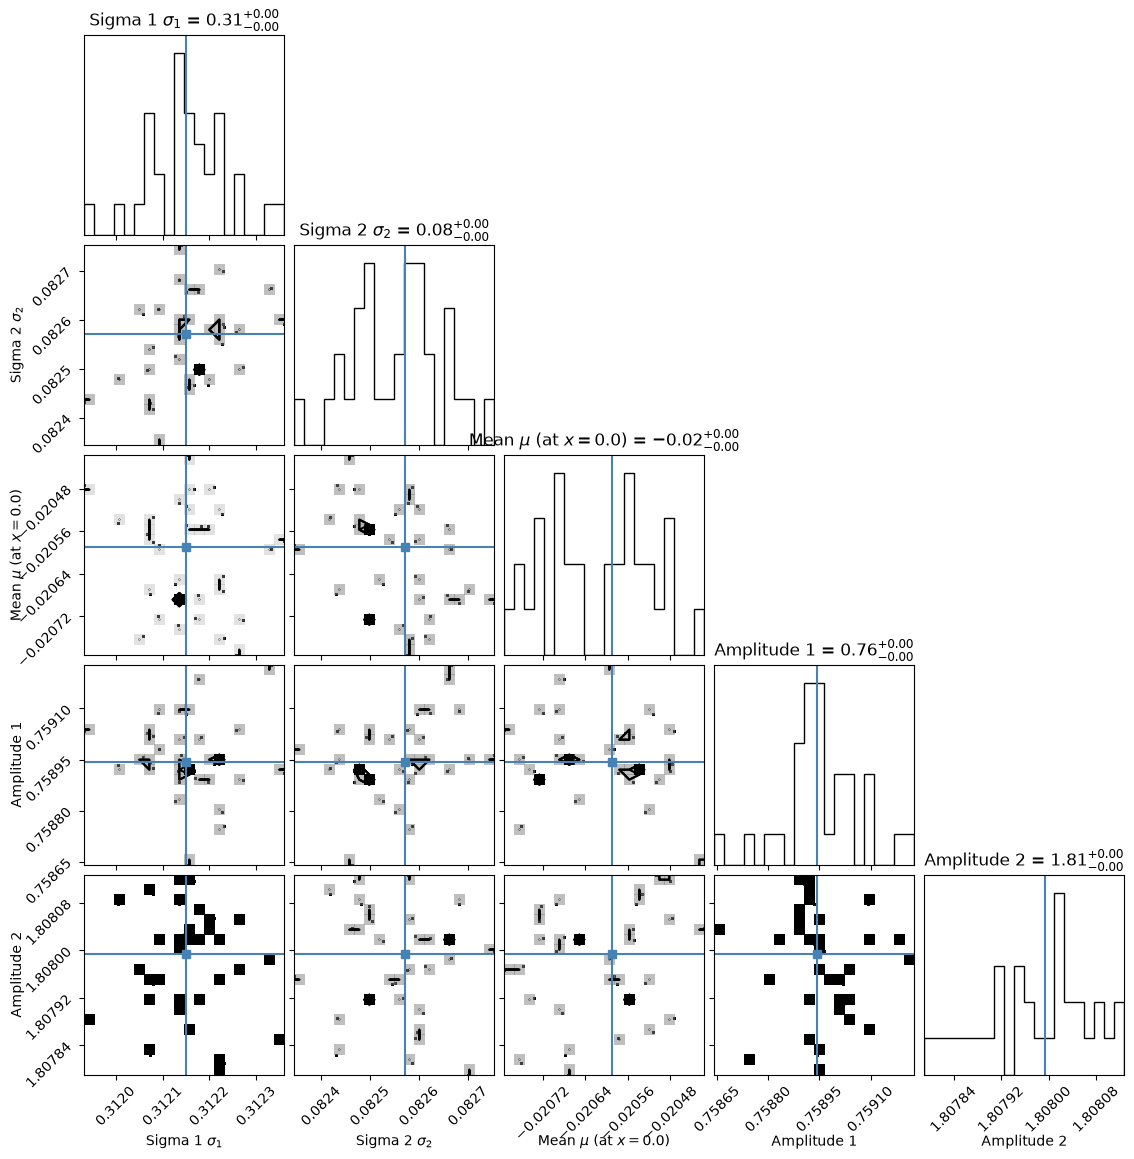

Reduced chi squared = 178.983
Posterior: -1.473 -- 2.702, length = 86500
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.062, sig = 0.221, mean = -0.023, amplitude = 1.811, amplitude = 1.375


100%|██████████| 5000/5000 [00:06<00:00, 715.36it/s]


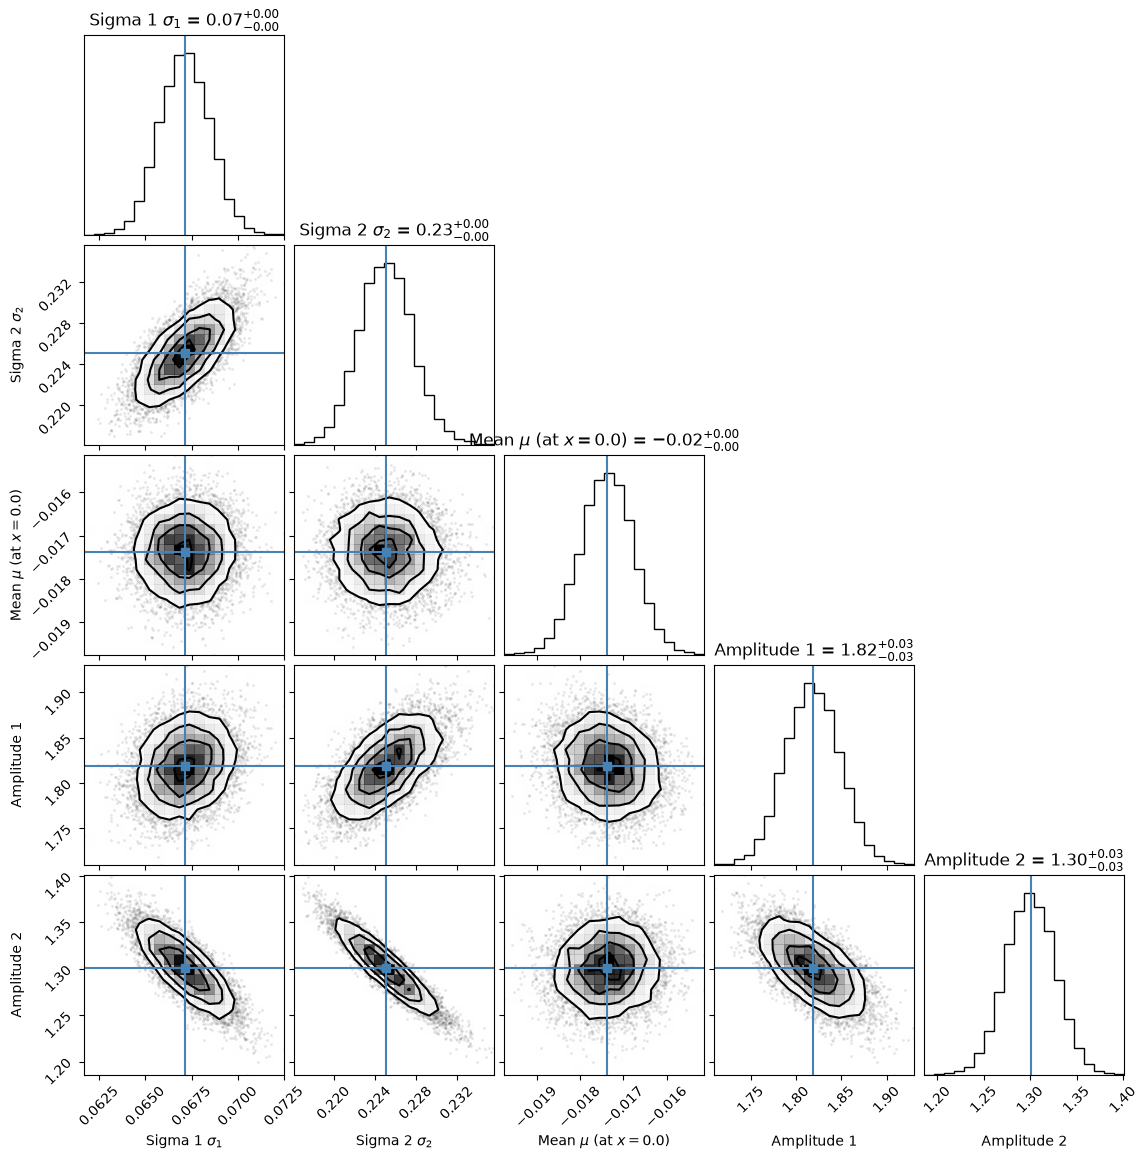

Reduced chi squared = 14.893
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m<8_z=9.0.h5
m bin:  [5, 8]
z bin:  [9.5, 10.5]
Number of gals in bin:  68
Guesses: sig = 0.182, sig = 0.500, mean = -0.018, amplitude = 0.768, amplitude = 0.517


100%|██████████| 5000/5000 [00:06<00:00, 752.01it/s]


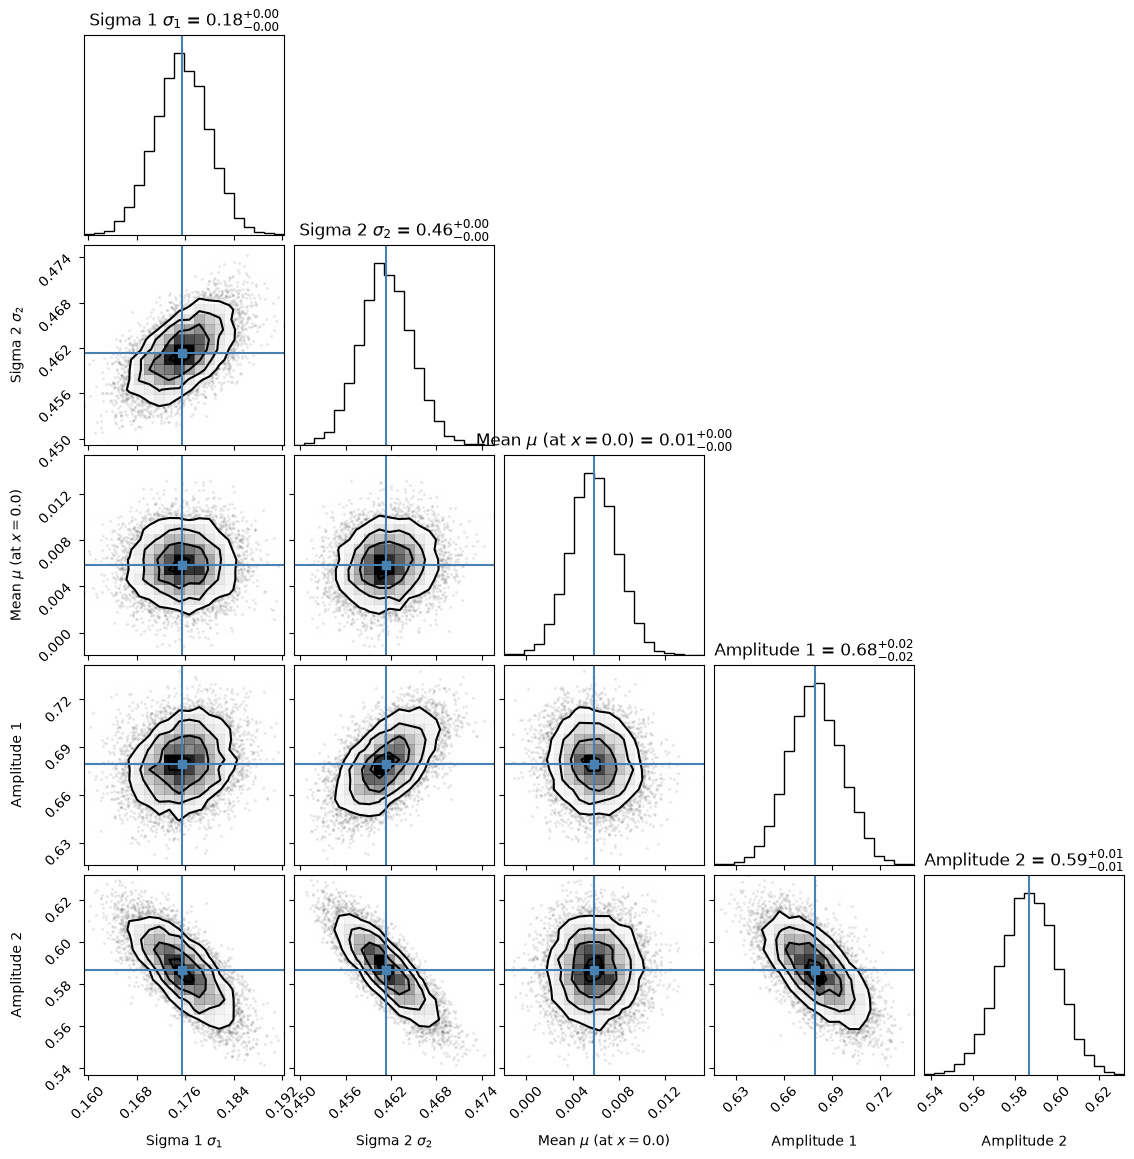

Reduced chi squared = 16.825
Posterior: -1.663 -- 3.064, length = 34000
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.173, sig = 0.489, mean = -0.018, amplitude = 0.755, amplitude = 0.546


100%|██████████| 5000/5000 [00:06<00:00, 767.80it/s]


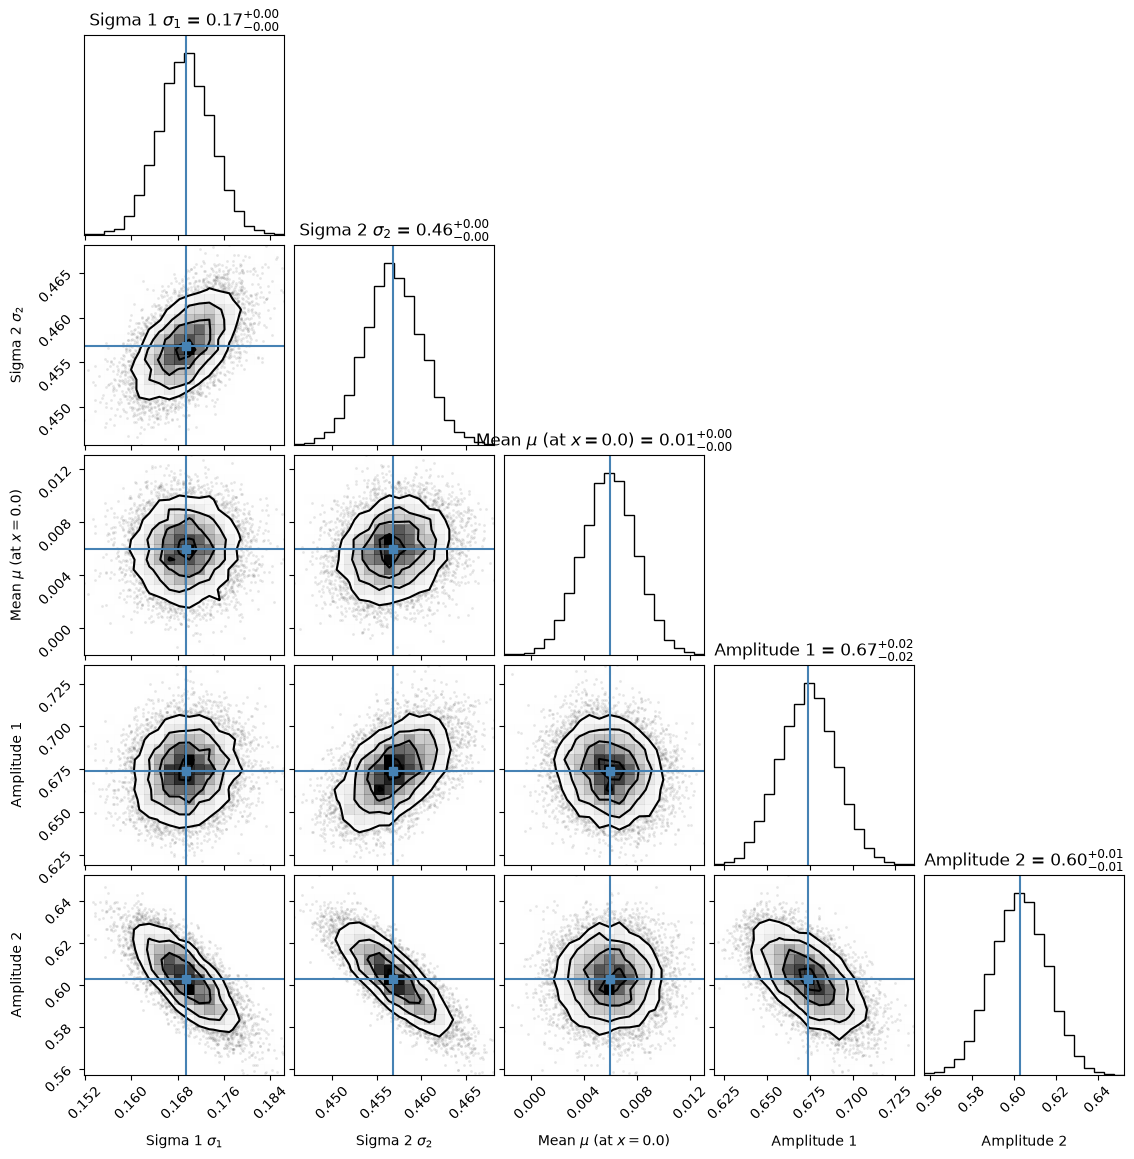

Reduced chi squared = 17.366
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m<8_z=10.0.h5
m bin:  [5, 8]
z bin:  [10.5, 11.5]
Number of gals in bin:  40
Guesses: sig = 0.138, sig = 0.498, mean = -0.039, amplitude = 0.395, amplitude = 0.680


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2382.46it/s]


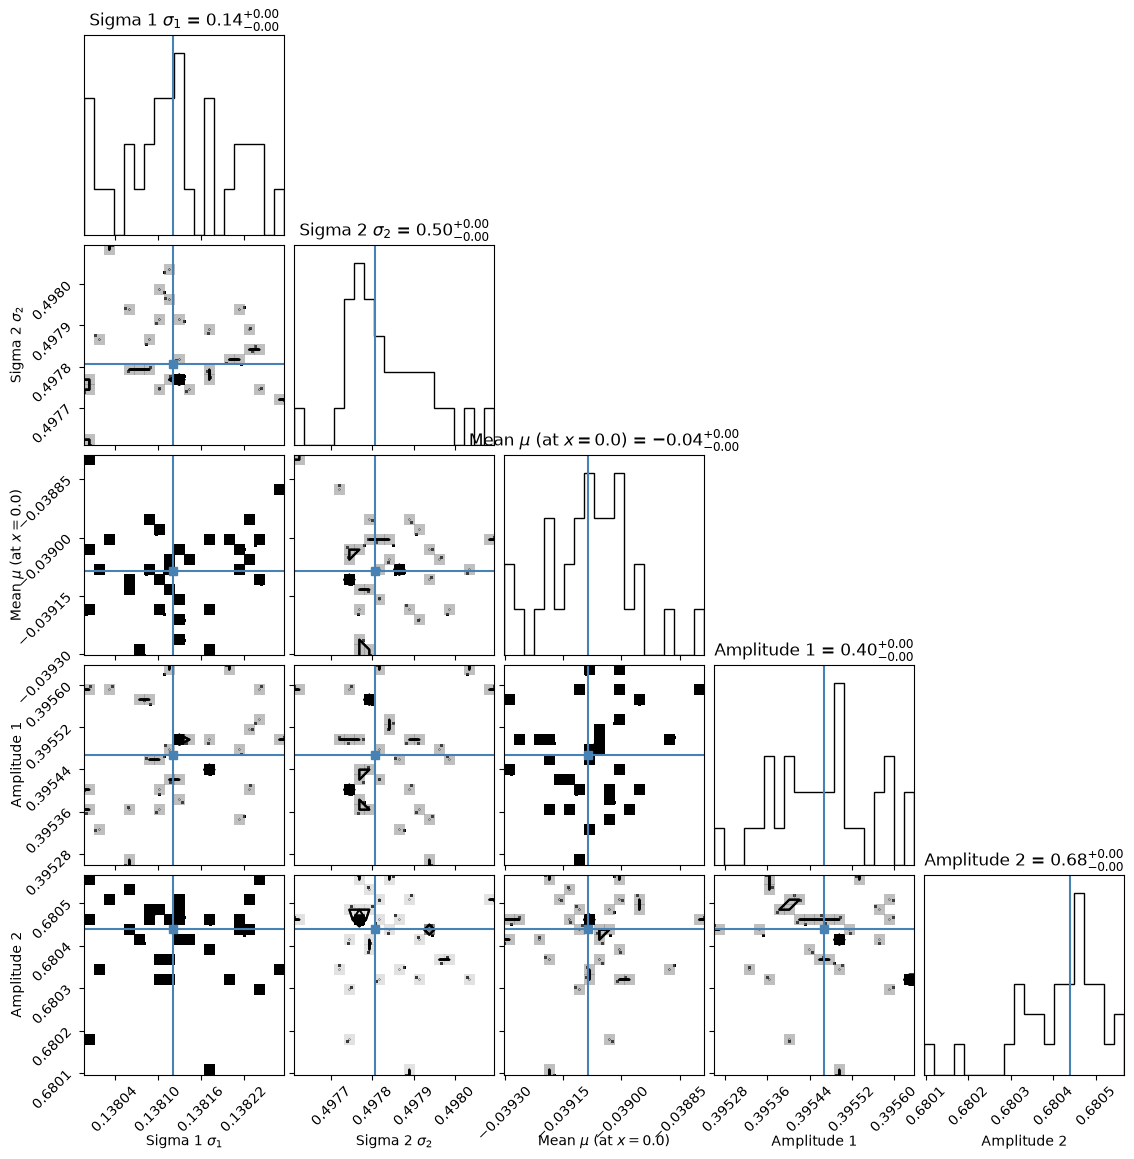

Reduced chi squared = 40.337
Posterior: -1.220 -- 4.014, length = 20000
Tails too long, trimming posterior and refitting.
Guesses: sig = 0.492, sig = 0.126, mean = -0.043, amplitude = 0.697, amplitude = 0.408


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:02<00:00, 2183.41it/s]


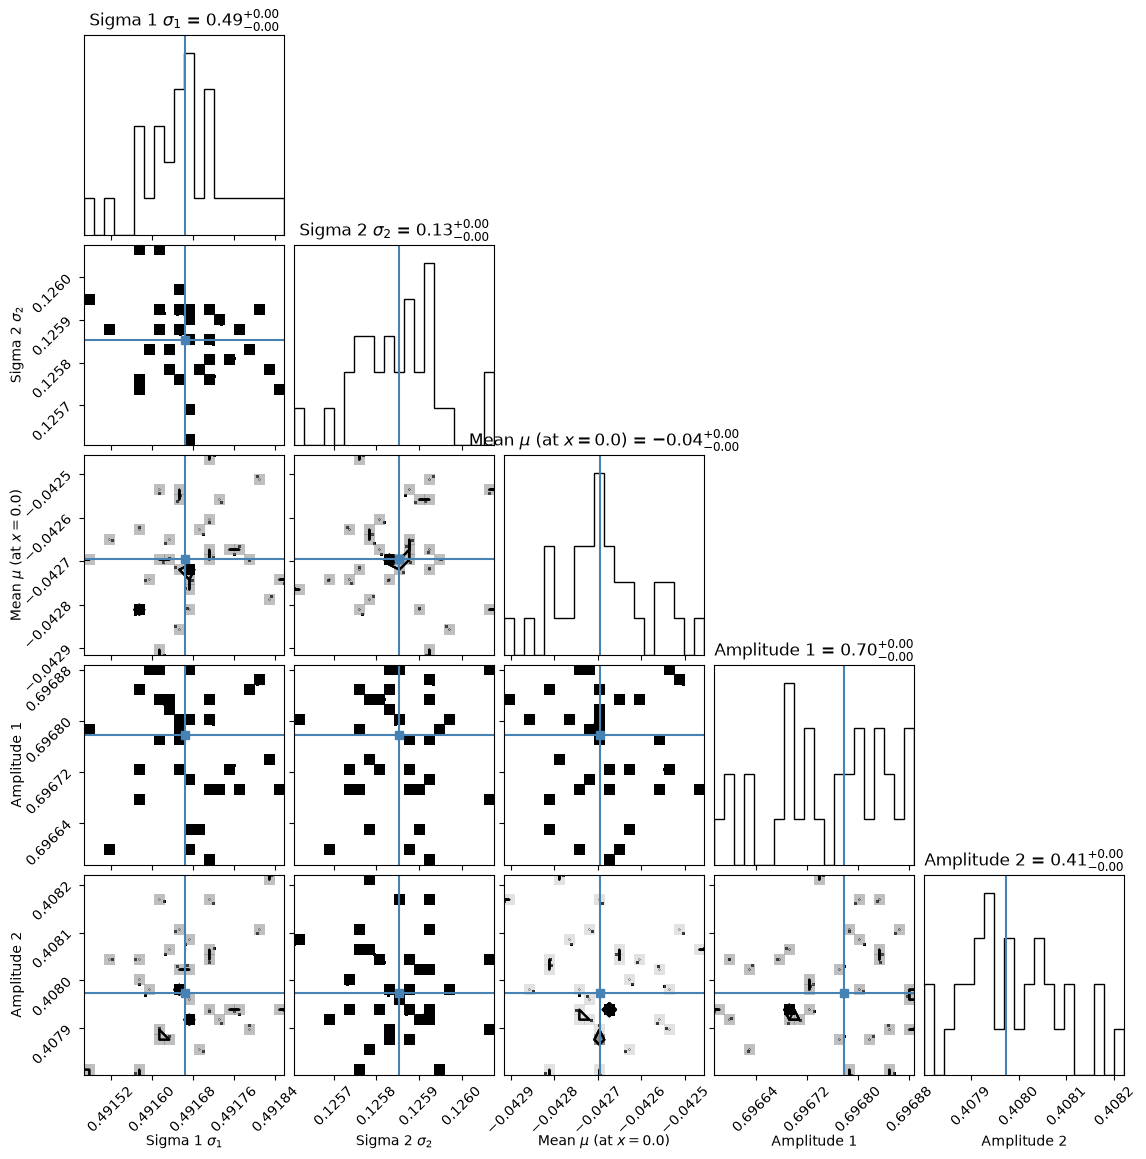

Reduced chi squared = 36.899
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m<8_z=11.0.h5
m bin:  [5, 8]
z bin:  [11.5, 13.5]
Number of gals in bin:  20
Guesses: sig = 0.561, sig = 0.561, mean = -0.013, amplitude = 0.372, amplitude = 0.372


  0%|          | 0/5000 [00:00<?, ?it/s]/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 5000/5000 [00:06<00:00, 788.84it/s]


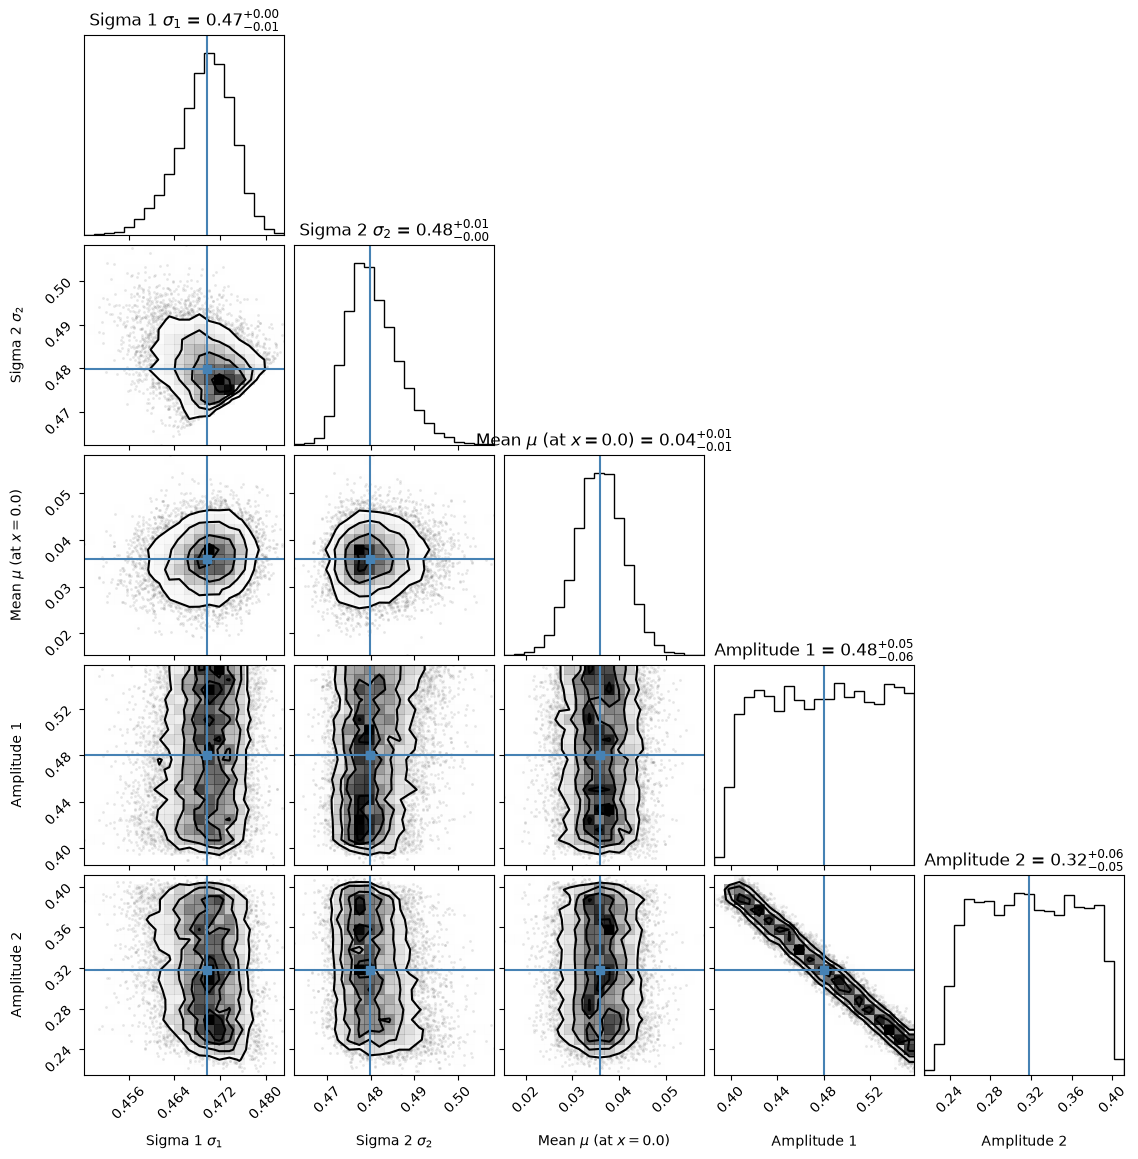

Reduced chi squared = 13.656
Posterior: -1.096 -- 1.436, length = 10000
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Double_gaussian_fit_results/results_table_m<8_z=12.5.h5


<Figure size 640x480 with 0 Axes>

In [81]:
if __name__ == "__main__":

    with fits.open('/raid/scratch/work/alberttg/Masters_project/Data_products/First_sample_table.fits') as hdu:

        sample_table = hdu[1].data
    sample_table = Table(sample_table)

    SFH_models = ["Bagpipes_sfh_cont_bursty_zEAZYsfhzblueagn_3.0,10.0Myr_Calzetti_log_10_Z_log_10_BPASS_zfix"]

    get_posterior(sample_table, SFH_models[0], refit=True)